# NoiseSimLimit_v4


## Motivation

使用 Salting 的方法，在事件率较低的时候，通过一阶近似可以给出轻暗物质的保守估计；但是事件率过高时，Salting 给出的估计并不一定保守。此时可以通过计算暗物质信号的各阶矩来进行估计。

## 最简单的数学过程

最简单的散粒噪声信号满足
$$x(t)=s(t)+n(t)$$
其中
$$s(t)=\sum_{i=1}^{N}E_i p_0(t-t_i)$$
而 $n(t)$ 是高斯白噪声，$p_0(t-t_i)$ 是信号 template。

具体地，
$$N\sim\mathrm{Poisson}(RT),\qquad
R(\sigma_\chi)=\int dE\,\frac{dR}{dE}(E;\sigma_\chi)$$
$$t_i\sim\mathrm{Uniform}(0,T),\qquad
E_i\sim p(E)=\frac{1}{R}\frac{dR}{dE}.$$

### 理论矩

只考虑 shot-noise signal：
$$s(t)=\sum_i E_i p_0(t-t_i).$$
定义
$$M_k\equiv R\langle E^k\rangle
=\int dE\,E^k\frac{dR}{dE}.$$

时域中，$s^q(t)$ 可以按照同一事件和不同事件的组合计算；实际情况下用 Monte Carlo 计算。

频域中
$$P_0(\omega)=\int dt\,p_0(t)e^{i\omega t},\qquad
p_0(t)=\int\frac{d\omega}{2\pi}P_0(\omega)e^{-i\omega t},$$
因此
$$S(\omega)=P_0(\omega)\sum_iE_i e^{i\omega t_i}.$$

### 测量矩和协方差

按足够长的间隔抽样，使样本近似独立。对抽样得到的 $E_{\mathrm{hist}}[k]$ 定义
$$\mu=\frac1K\sum_{k=1}^K E_{\mathrm{hist}}[k],\qquad
x_k=E_{\mathrm{hist}}[k]-\mu,$$
$$m_n=\frac1K\sum_{k=1}^Kx_k^n.$$

测量向量为
$$\hat{m}=(\hat m_{q_1},\hat m_{q_2},\ldots)^T,$$
参考截面下的理论响应记为 $\theta$，协方差为
$$\Sigma=\mathrm{Cov}(\hat m,\hat m).$$

对于独立同分布抽样，
$$\mathbb E[m_pm_q]
=\frac{1}{K^2}\left[K\mu_{p+q}+K(K-1)\mu_p\mu_q\right],$$
所以
$$\Sigma_{pq}=\mathrm{Cov}(m_p,m_q)
=\frac{\mu_{p+q}-\mu_p\mu_q}{K}.$$

### 参数估计

令
$$\alpha=\frac{\sigma_\chi}{\sigma_0},\qquad
\mathbb E[\hat m]\simeq\alpha\theta.$$
高斯 likelihood 为
$$\mathcal L(\alpha)\propto
\exp\left[-\frac12(\hat m-\alpha\theta)^T
\Sigma^{-1}(\hat m-\alpha\theta)\right].$$
极大似然估计为
$$\hat\alpha=
\frac{\theta^T\Sigma^{-1}\hat m}
{\theta^T\Sigma^{-1}\theta},$$
且
$$\mathrm{Var}(\hat\alpha)=
\frac1{\theta^T\Sigma^{-1}\theta}.$$
如果存在高斯噪声，它会给二阶矩带来常数 bias，需要在解释结果时区分该 bias 与统计波动。

## Intuitive explain
整个过程相当于是：在各阶矩张成的空间中，测量谱的数据对应的就是空间中的一个点。而对于参数估计，理论能谱给出的矩规定了矢量的方向，参数估计给出的则是矢量的长度。下面给出二维平面的例子，分别在低事例率和高事例率下。

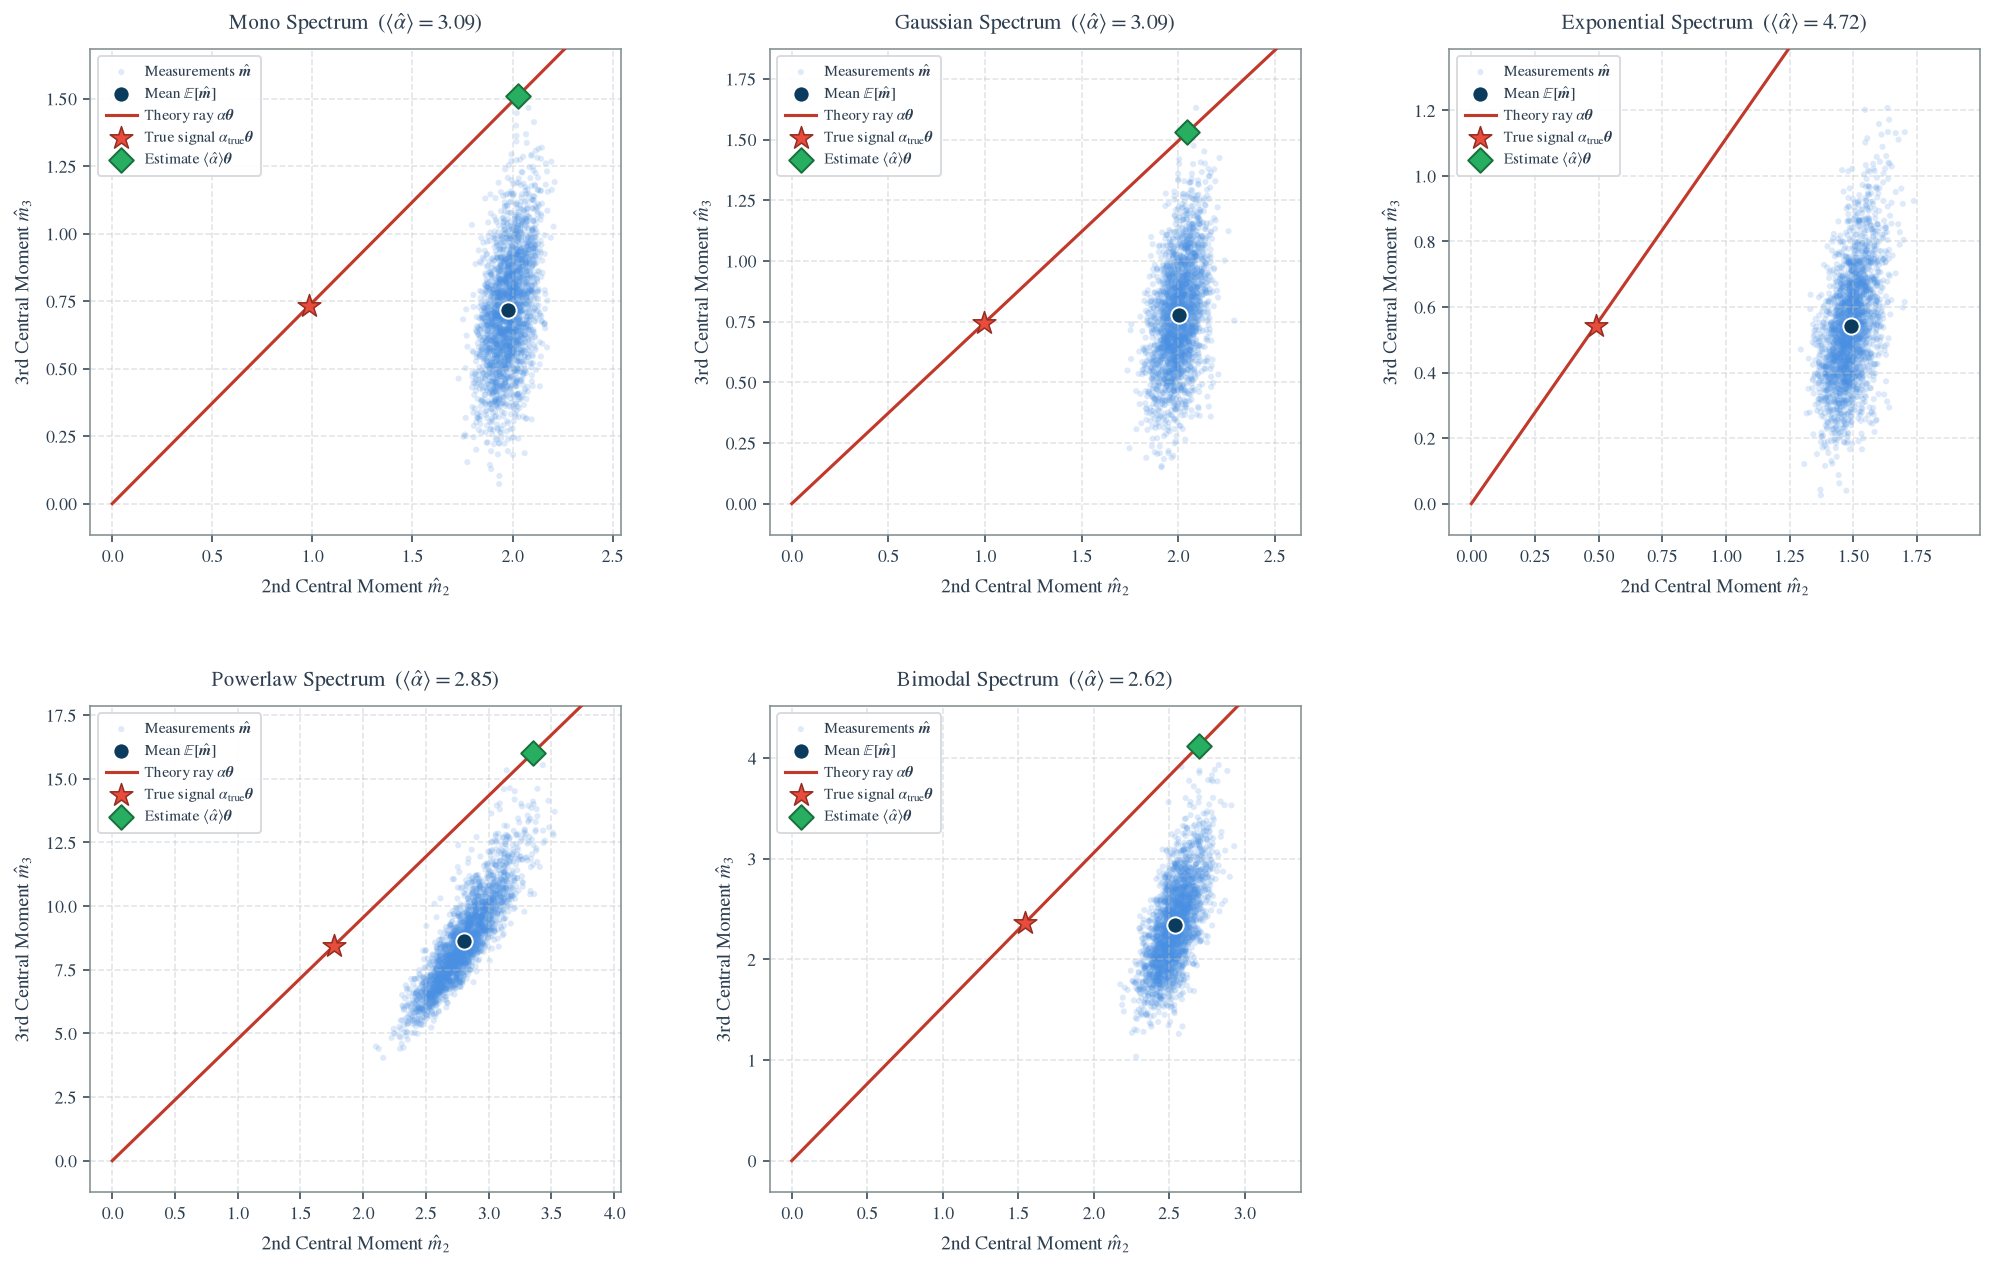

In [98]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

np.random.seed(42)


gauss_std = 1.0       # gauss noise standard应当在频域上定义高斯噪声
rate_0 = 1.2          # low rate
alpha_true = 1.5      #  \alpha_{true} = \sigma_{\chi} / \sigma_0
rate_true = alpha_true * rate_0  # R(sigma_chi) = alpha_true * R_0


t_obs = 6000.0         # observation time
tau_r, tau_f = 0.05, 0.8
t_pulse_len = 10.0

t_burn = 15.0
t_total = t_burn + t_obs + t_pulse_len # 不是必要的

dt = 0.005           # step
t_grid = np.arange(0.0, t_total, dt)
N_pts = len(t_grid)

# template
t_p = np.arange(0.0, t_pulse_len, dt)
template = np.exp(-t_p / tau_f) - np.exp(-t_p / tau_r)
template = template / np.max(template)

# i.i.d. step
t_step = 5.0 * (tau_f + tau_r)
step_sample = int(np.ceil(t_step / dt))

# time index
i_start = int(t_burn / dt)
i_end = int((t_burn + t_obs) / dt)

# shot noise waveform generation and moment calculation
def generate_single_realization(rate_val, energies_func, observation_time=None):
    """
    生成泊松事件，并且先在频域上相乘然后再卷积回去（这样复杂度是O(N log N)而不是O(N^2)）
    """
    local_t_obs = t_obs if observation_time is None else float(observation_time)
    local_t_total = t_burn + local_t_obs + t_pulse_len
    local_N_pts = int(np.ceil(local_t_total / dt))
    local_i_end = int((t_burn + local_t_obs) / dt)

    n_events = np.random.poisson(rate_val * local_t_total)
    t_events = np.random.uniform(0.0, local_t_total, n_events)
    e_events = energies_func(n_events)
    
    delta_train = np.zeros(local_N_pts, dtype=np.float64)
    indices = np.clip((t_events / dt).astype(int), 0, local_N_pts - 1)
    np.add.at(delta_train, indices, e_events)
    
    s = fftconvolve(delta_train, template, mode='full')[:local_N_pts]#python的fft效率较低，可以使用效率更高的
    s_steady = s[i_start:local_i_end:step_sample]
    return s_steady


# caculate the moment
def cal_moments_2d(data):
    
    c = data - np.mean(data)
    return np.mean(c**2), np.mean(c**3)

# spectrum
def sample_spectrum(spectrum_type, n_events):
    if spectrum_type == 'mono':
        return np.full(n_events, 1.0)
    elif spectrum_type == 'gaussian':
        return np.clip(np.random.normal(1.0, 0.15, n_events), 0.01, None)
    elif spectrum_type == 'exponential':
        return np.random.exponential(scale=0.5, size=n_events)
    elif spectrum_type == 'powerlaw':
        u = np.random.uniform(0.0, 1.0, n_events)
        E_min, gamma = 0.05, 1.8
        e = E_min * (1.0 - u) ** (-1.0 / (gamma - 1.0))
        return np.clip(e, a_min=E_min, a_max=8.0)
    elif spectrum_type == 'bimodal':
        w = np.random.binomial(1, 0.3, n_events)
        e = (1 - w) * np.random.normal(0.4, 0.05, n_events) + w * np.random.normal(2.2, 0.08, n_events)
        return np.clip(e, a_min=0.01, a_max=None)
    else:
        raise ValueError("Unknown spectrum type")

# Monte Carlo
def simulate_spectrum_experiment(spectrum_type, n_experiments=2500):
    m2_ref_list, m3_ref_list = [], []
    for _ in range(80):
        s_ref = generate_single_realization(rate_0, lambda n, sp=spectrum_type: sample_spectrum(sp, n))
        m2_r, m3_r = cal_moments_2d(s_ref)
        m2_ref_list.append(m2_r)
        m3_ref_list.append(m3_r)
    theta = np.array([np.mean(m2_ref_list), np.mean(m3_ref_list)])
    
    m_obs_list = []
    for _ in range(n_experiments):
        s_true = generate_single_realization(rate_true, lambda n, sp=spectrum_type: sample_spectrum(sp, n))
        noise = np.random.normal(0.0, gauss_std, len(s_true))
        x_obs = s_true + noise
        m2, m3 = cal_moments_2d(x_obs)
        m_obs_list.append([m2, m3])
    m_obs_arr = np.array(m_obs_list)
    
    Sigma = np.cov(m_obs_arr, rowvar=False)
    Sigma_inv = np.linalg.inv(Sigma)
    
    denom = theta.T @ Sigma_inv @ theta
    alpha_hats = (m_obs_arr @ Sigma_inv @ theta) / denom
    
    return {
        'type': spectrum_type,
        'theta': theta,
        'm_obs_arr': m_obs_arr,
        'mean_obs': np.mean(m_obs_arr, axis=0),
        'alpha_hats': alpha_hats,
        'alpha_true': alpha_true
    }

# plot
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['STIXGeneral', 'Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'legend.fontsize': 8,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'text.color': '#2C3E50',
    'axes.labelcolor': '#2C3E50',
    'xtick.color': '#2C3E50',
    'ytick.color': '#2C3E50',
})

def plot_all_spectra(output_name="consistent_low_rate_moments.png", n_experiments=2500):
    spectra = ['mono', 'gaussian', 'exponential', 'powerlaw', 'bimodal']
    fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), dpi=140)
    axes = axes.flatten()
    
    for i, spec in enumerate(spectra):
        ax = axes[i]
        res = simulate_spectrum_experiment(spec, n_experiments=n_experiments)
        
        theta = res['theta']
        m_obs = res['m_obs_arr']
        mean_obs = res['mean_obs']
        alpha_hats = res['alpha_hats']
        mean_alpha = np.mean(alpha_hats)
        
        all_x = np.concatenate([m_obs[:, 0], [0, alpha_true * theta[0]]])
        all_y = np.concatenate([m_obs[:, 1], [0, alpha_true * theta[1]]])
        x_min, x_max = np.min(all_x), np.max(all_x)
        y_min, y_max = np.min(all_y), np.max(all_y)
        
        dx = x_max - x_min if x_max > x_min else 1.0
        dy = y_max - y_min if y_max > y_min else 1.0
        
        plot_x_min = min(0.0, x_min) - 0.05 * dx
        plot_x_max = x_max + 0.15 * dx
        plot_y_min = min(0.0, y_min) - 0.08 * dy
        plot_y_max = y_max + 0.15 * dy
        
        # 测量散点
        ax.scatter(m_obs[:, 0], m_obs[:, 1], 
                   color='#4A90E2', alpha=0.18, s=10, 
                   edgecolors='none', label=r'Measurements $\hat{\boldsymbol{m}}$')
        
        # 测量散点的均值
        ax.scatter(mean_obs[0], mean_obs[1], 
                   color='#0B3C5D', s=70, marker='o', 
                   edgecolors='white', linewidth=1.0, zorder=5, 
                   label=r'Mean $\mathbb{E}[\hat{\boldsymbol{m}}]$')
        
        # 理论给出的矢量方向
        scale_ray = plot_x_max / theta[0] if theta[0] > 1e-6 else 2.5
        ax.plot([0, scale_ray * theta[0]], [0, scale_ray * theta[1]], 
                color='#C0392B', lw=1.6, linestyle='-', zorder=4, 
                label=r'Theory ray $\alpha \boldsymbol{\theta}$')
        
        # 先验给出的截面
        true_pt = alpha_true * theta
        ax.scatter(true_pt[0], true_pt[1], 
                   color='#E74C3C', marker='*', s=150, 
                   edgecolors='#962D22', linewidth=0.8, zorder=6, 
                   label=r'True signal $\alpha_{\mathrm{true}} \boldsymbol{\theta}$')
        
        # 估计得到的点
        proj_pt = mean_alpha * theta
        ax.scatter(proj_pt[0], proj_pt[1], 
                   color='#27AE60', s=80, marker='D', 
                   edgecolors='#196F3D', linewidth=1.0, zorder=7, 
                   label=r'Estimate $\langle\hat{\alpha}\rangle \boldsymbol{\theta}$')
        
        ax.set_xlim(plot_x_min, plot_x_max)
        ax.set_ylim(plot_y_min, plot_y_max)
        
        ax.set_xlabel(r'2nd Central Moment $\hat{m}_2$', labelpad=6)
        ax.set_ylabel(r'3rd Central Moment $\hat{m}_3$', labelpad=6)
        ax.set_title(f"{spec.capitalize()} Spectrum  " + r"($\langle\hat{\alpha}\rangle = " + f"{mean_alpha:.2f}" + r"$)", pad=10)
        
        ax.grid(True, linestyle='--', color='#BDC3C7', alpha=0.45, zorder=0)
        for spine in ax.spines.values():
            spine.set_color('#7F8C8D')
            spine.set_linewidth(0.8)
            
        ax.tick_params(direction='out', length=3.5, width=0.8)
        ax.legend(loc='upper left', frameon=True, facecolor='white', 
                  edgecolor='#D5D8DC', framealpha=0.92, 
                  borderpad=0.5, labelspacing=0.4, handletextpad=0.5)

    fig.delaxes(axes[5])
    plt.subplots_adjust(left=0.07, right=0.97, bottom=0.08, top=0.94, wspace=0.28, hspace=0.35)
    plt.savefig(output_name, dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == '__main__':
    plot_all_spectra()


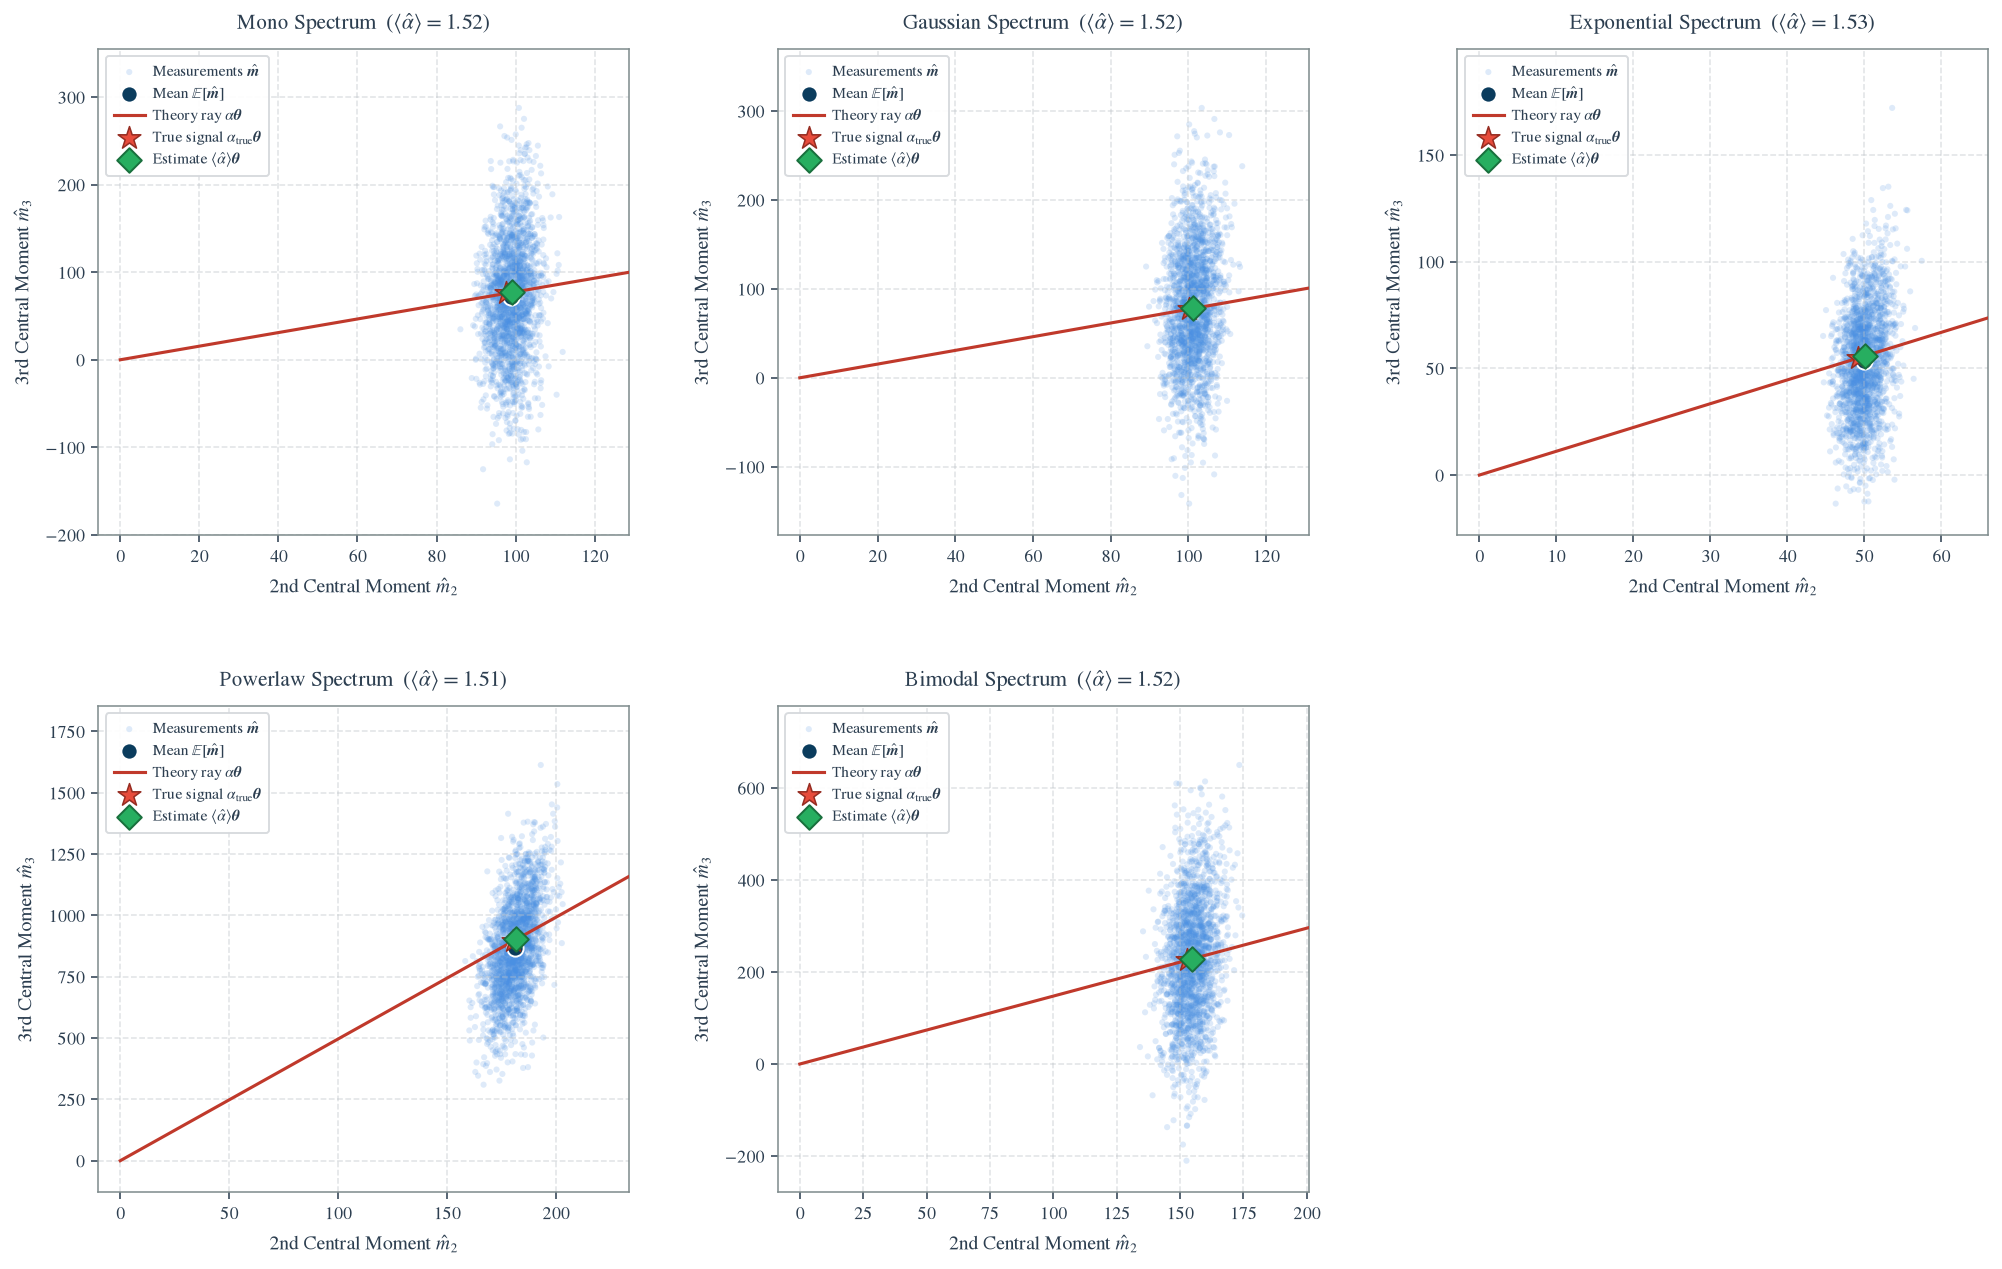

In [99]:
# High-rate case: reuse the same Monte Carlo and moment estimator.
rate_0 = 120.0
rate_true = alpha_true * rate_0
plot_all_spectra("consistent_high_rate_moments.png", n_experiments=2000)

## Part1:高阶的central moments真的合适吗？是否应该用cumulant？
先从一个普通随机变量 $X$ 开始。它的 moment generating function 是
$$M_X(t) = \langle e^{tX} \rangle.$$
定义 cumulant generating function
$$K_X(t) \equiv \log M_X(t) = \log \langle e^{tX} \rangle.$$
然后第 $n$ 阶 cumulant 定义为
$$\kappa_n(X) = \left. \frac{d^n K_X(t)}{dt^n} \right\vert{}_{t=0}.$$
等价地，$$K_X(t) = \sum_{n=1}^{\infty} \kappa_n \frac{t^n}{n!}.$$
而普通的 moments 是
$$M_X(t) = 1 + \sum_{n=1}^{\infty} \langle X^n \rangle \frac{t^n}{n!}.$$
记   
$$\mu \equiv \langle X \rangle,$$
那么   
$$\mu_n^{(c)} = \langle (X - \mu)^n \rangle.$$
$$\kappa_1 = \mu$$
$$\kappa_2 = \mu_2^{(c)} = \mathrm{Var}(X)$$
$$\kappa_3 = \mu_3^{(c)}.$$
所以到三阶为止，实际上感觉不到“central moment”和“cumulant”的区别。但四阶及以上：   
$$\kappa_4 = \mu_4^{(c)} - 3 \left(\mu_2^{(c)}\right)^2$$
即
$$\mu_4^{(c)} = \kappa_4 + 3\kappa_2^2.$$
第五阶：
$$\kappa_5 = \mu_5^{(c)} - 10\mu_3^{(c)}\mu_2^{(c)}.$$
第六阶：
$$\kappa_6 = \mu_6^{(c)} - 15\mu_4^{(c)}\mu_2^{(c)} - 10(\mu_3^{(c)})^2 + 30(\mu_2^{(c)})^3.$$
假设
$$X = X_A + X_B,$$
而 $X_A, X_B$ 独立。那么
$$M_X(t) = \langle e^{t(X_A+X_B)} \rangle = M_A(t) M_B(t).$$
取 log：
$$K_X(t) = \log M_A(t) + \log M_B(t).$$
所以
$$\kappa_n(X_A + X_B) = \kappa_n(X_A) + \kappa_n(X_B).$$
所以不难发现是线性的。

假设观测量
$$S = \sum_{i=1}^{N} Y_i,$$
其中
$$N \sim \mathrm{Poisson}(\lambda)$$
是 DM event 数目，
假设 $Y_i$ IID，并且和 $N$ 独立。
我们计算
$$M_S(t) = \left\langle e^{t \sum_i Y_i} \right\rangle.$$
先固定 $N$。由于 events 独立，
$$\left\langle e^{t \sum_{i=1}^N Y_i} \right\rangle_{Y\vert{}N} = [M_Y(t)]^N.$$
因此
$$M_S(t) = \sum_{N=0}^{\infty} P(N) [M_Y(t)]^N.$$
泊松分布
$$P(N) = e^{-\lambda} \frac{\lambda^N}{N!}.$$
所以
$$\begin{aligned} M_S(t) &= e^{-\lambda} \sum_N \frac{[\lambda M_Y(t)]^N}{N!} \\ &= e^{-\lambda} e^{\lambda M_Y(t)} \\ &= e^{\lambda [M_Y(t) - 1]}. \end{aligned}$$
于是 cumulant generating function 是
$$K_S(t) = \lambda [M_Y(t) - 1].$$
现在展开单个事件的的 MGF：
$$M_Y(t) = 1 + \langle Y \rangle t + \frac{\langle Y^2 \rangle}{2!} t^2 + \frac{\langle Y^3 \rangle}{3!} t^3 + \cdots.$$
所以
$$K_S(t) = \lambda \sum_{n=1}^{\infty} \langle Y^n \rangle \frac{t^n}{n!}.$$
和定义
$$K_S(t) = \sum_n \kappa_n(S) \frac{t^n}{n!}$$
比较，立刻得到
$$\kappa_n(S) = \lambda \langle Y^n \rangle.$$
可以看到，cumulant正比于Rate，那么高阶中心矩就不正比于rate了。

如果观测为
$$x = s_\chi + n.$$
如果 $s_\chi, n$ 独立，那么 cumulants 相加：
$$\kappa_n[x] = \kappa_n[s_\chi] + \kappa_n[n].$$
Gaussian noise 满足
$$\kappa_n[n] = 0, \quad n > 2.$$
所以
$$\kappa_2[x] = \alpha\theta_2 + \kappa_2[n],$$
而
$$\kappa_n[x] = \alpha\theta_n, \quad n \ge 3$$



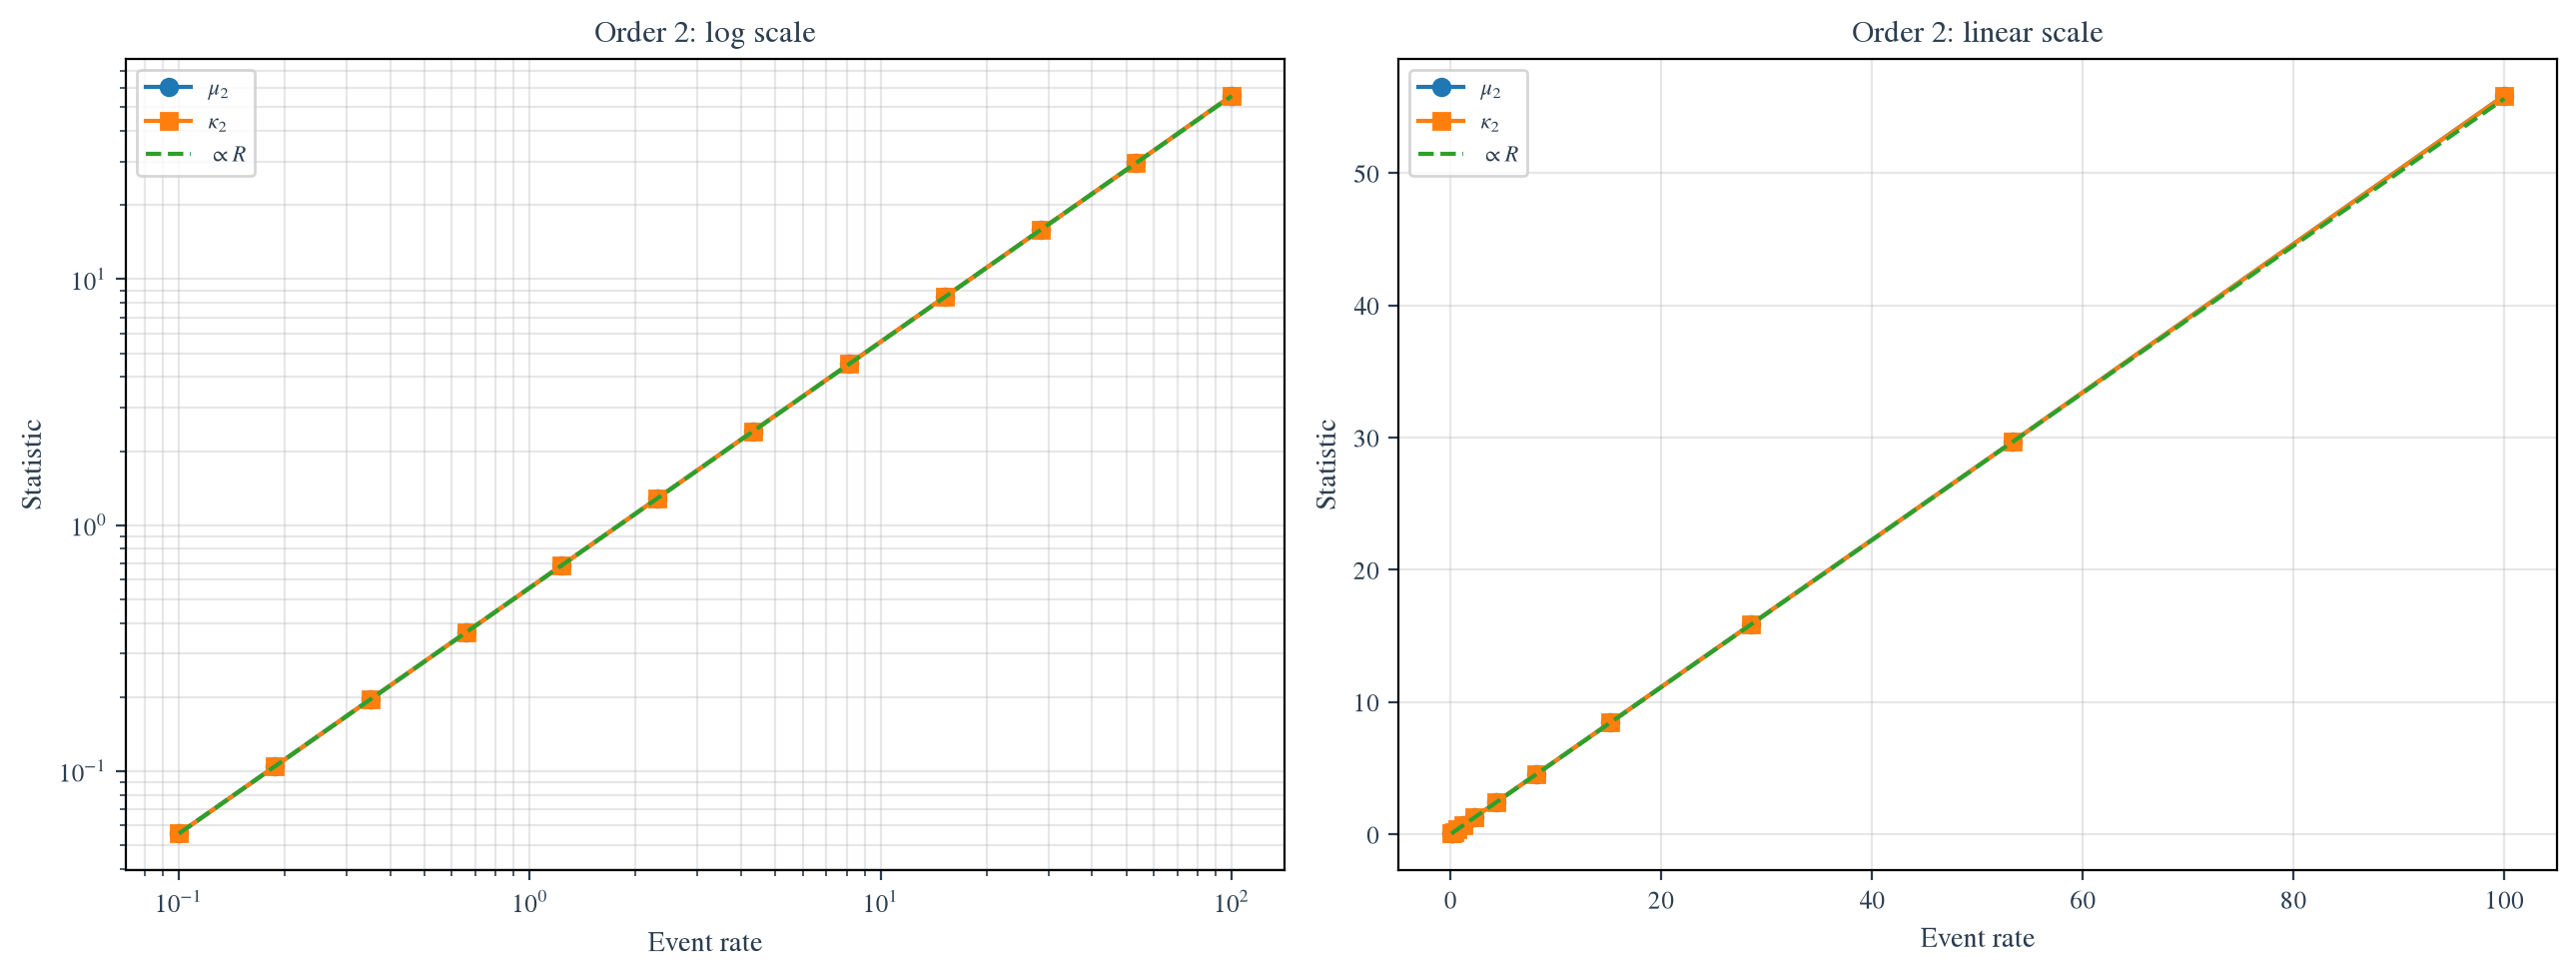

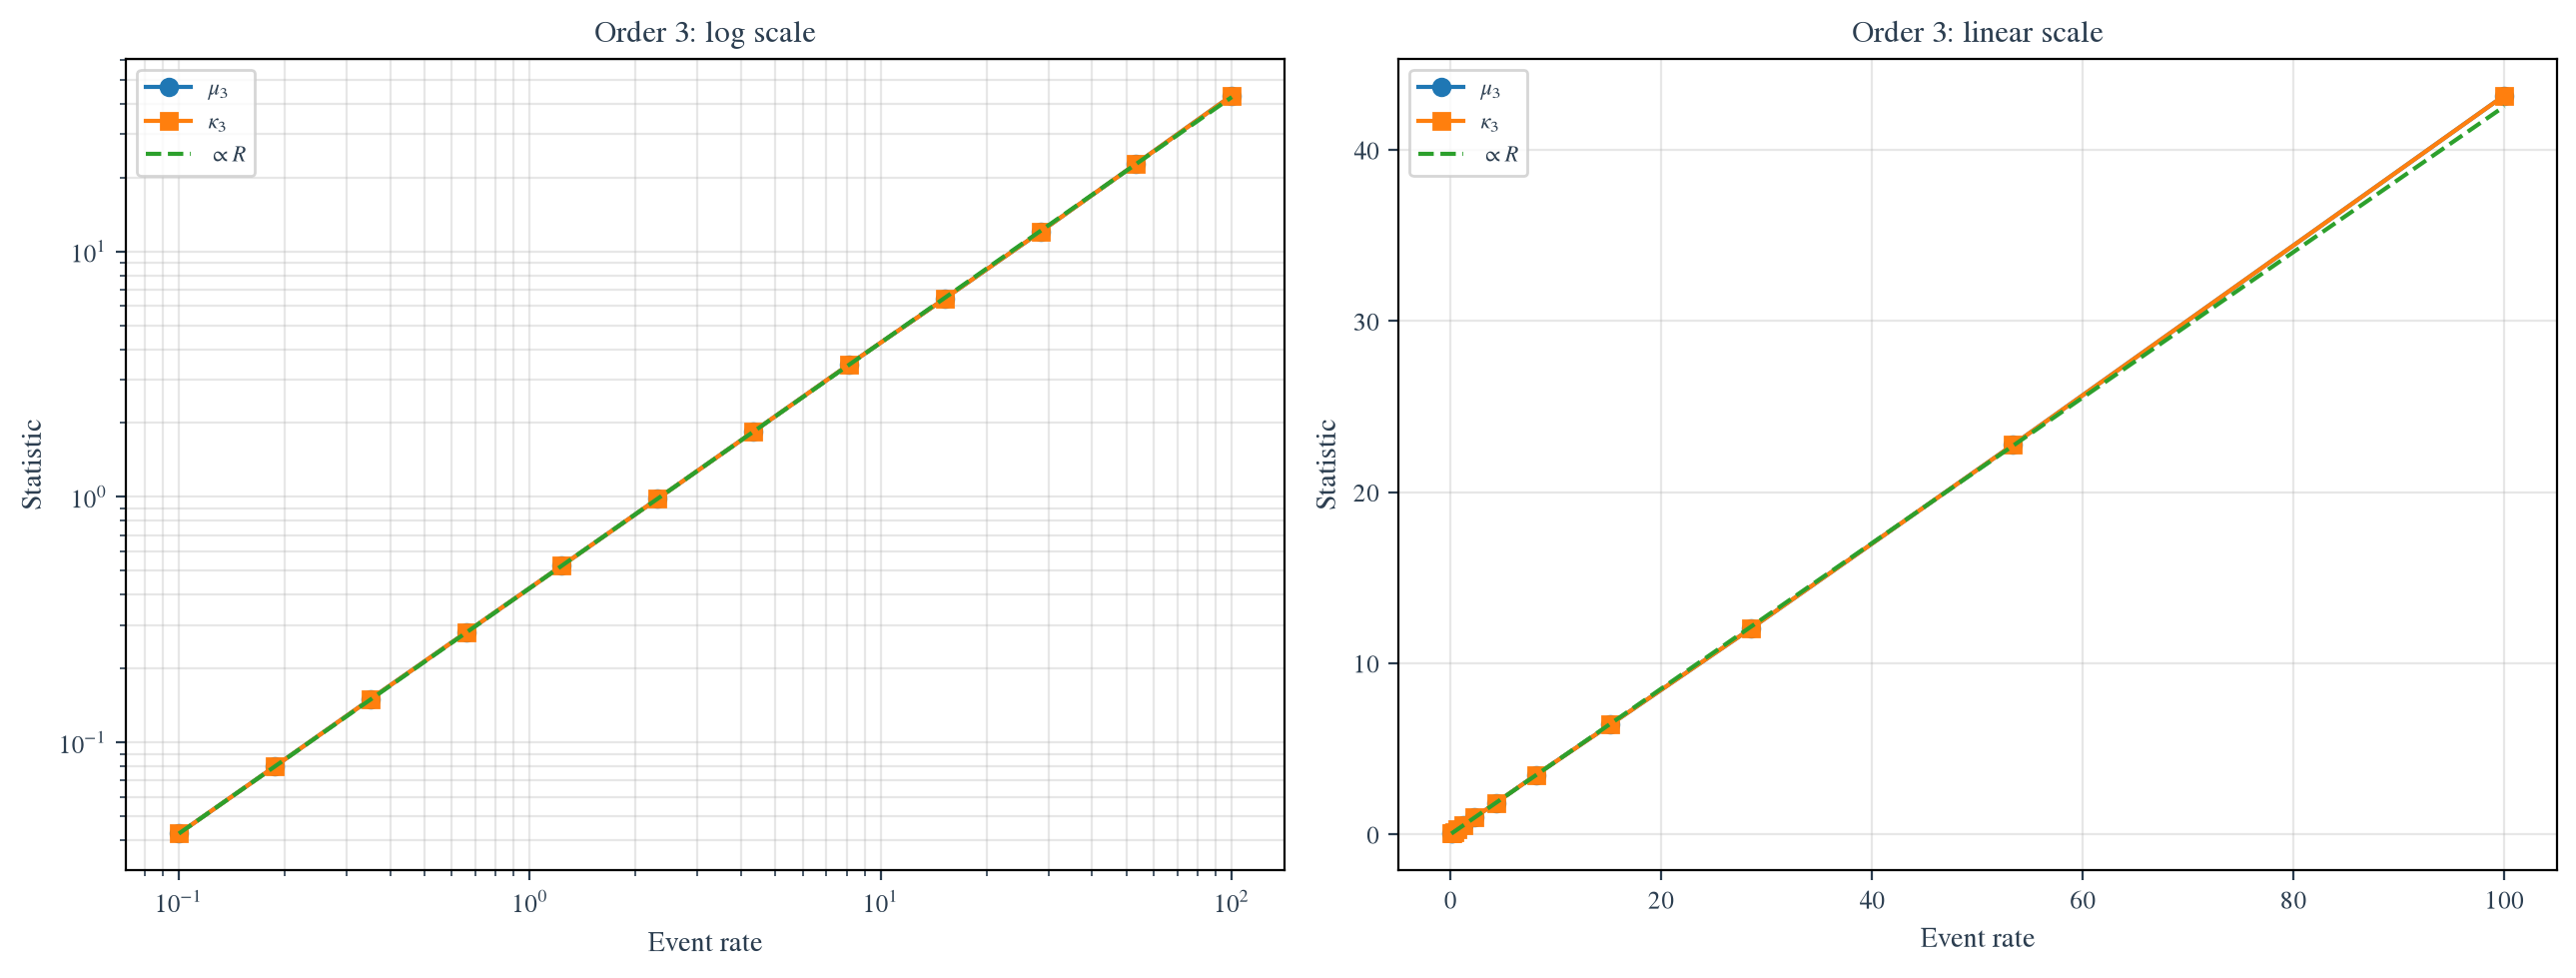

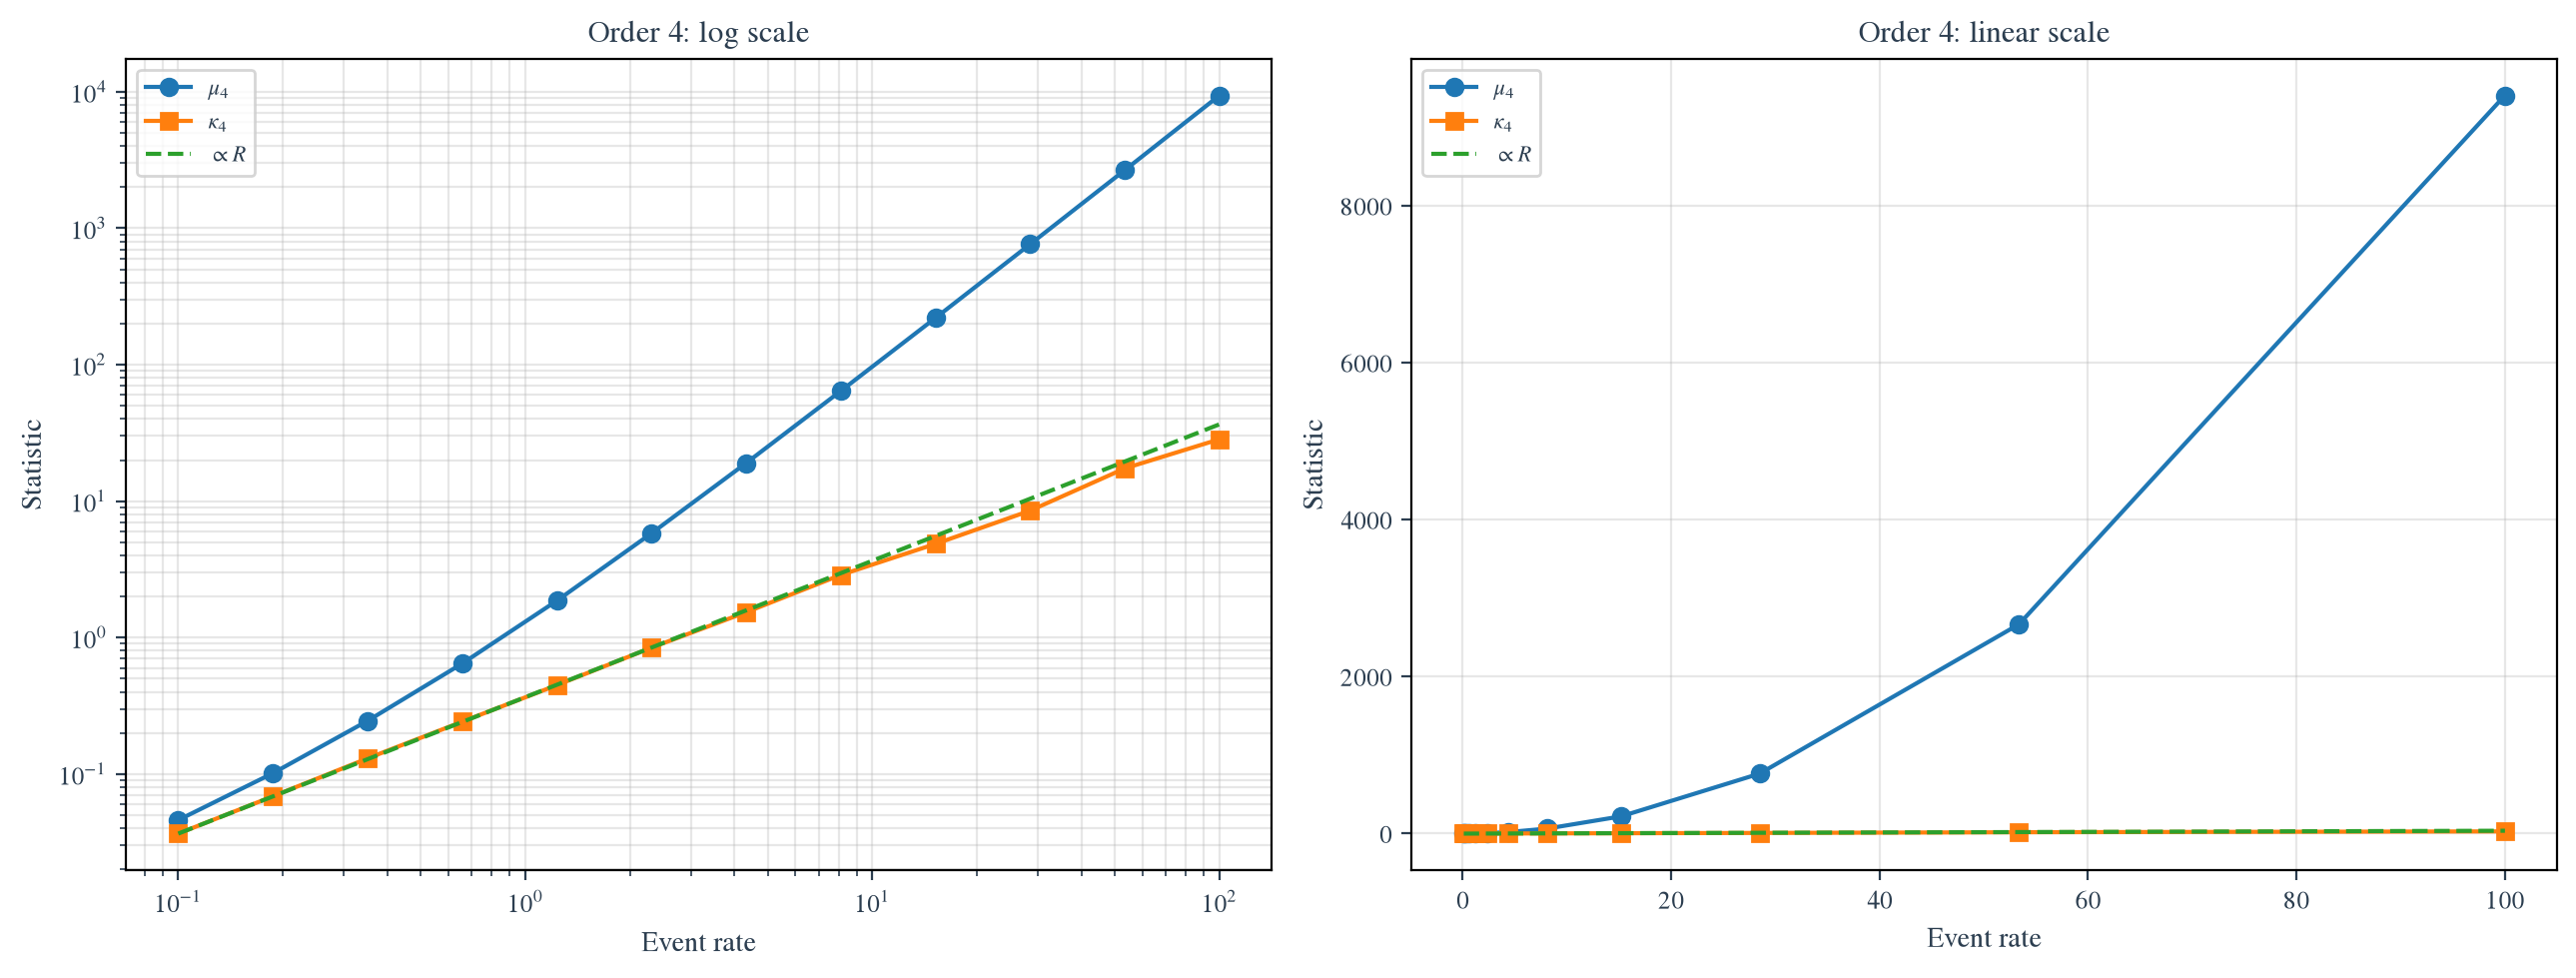

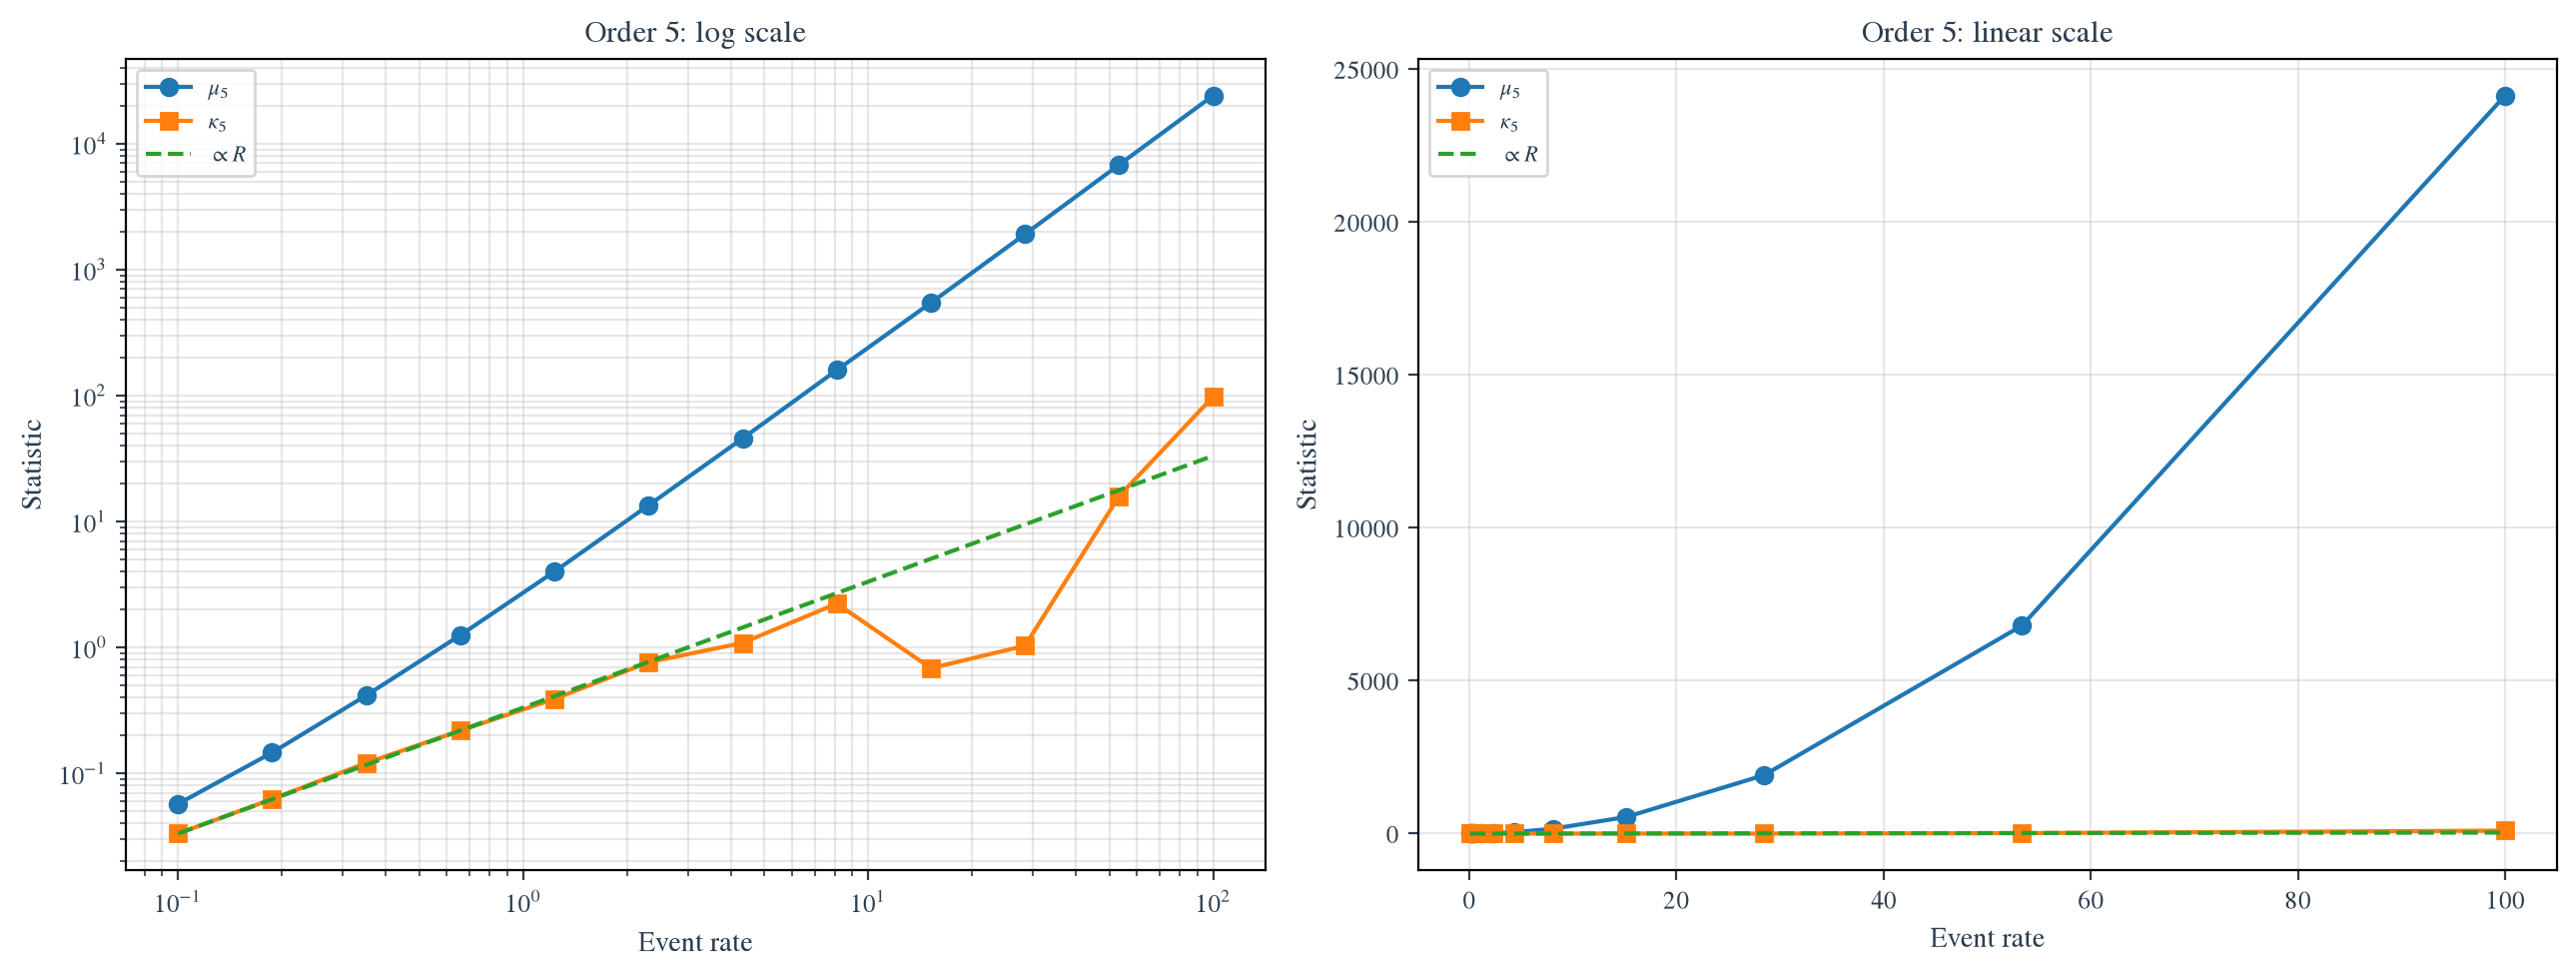

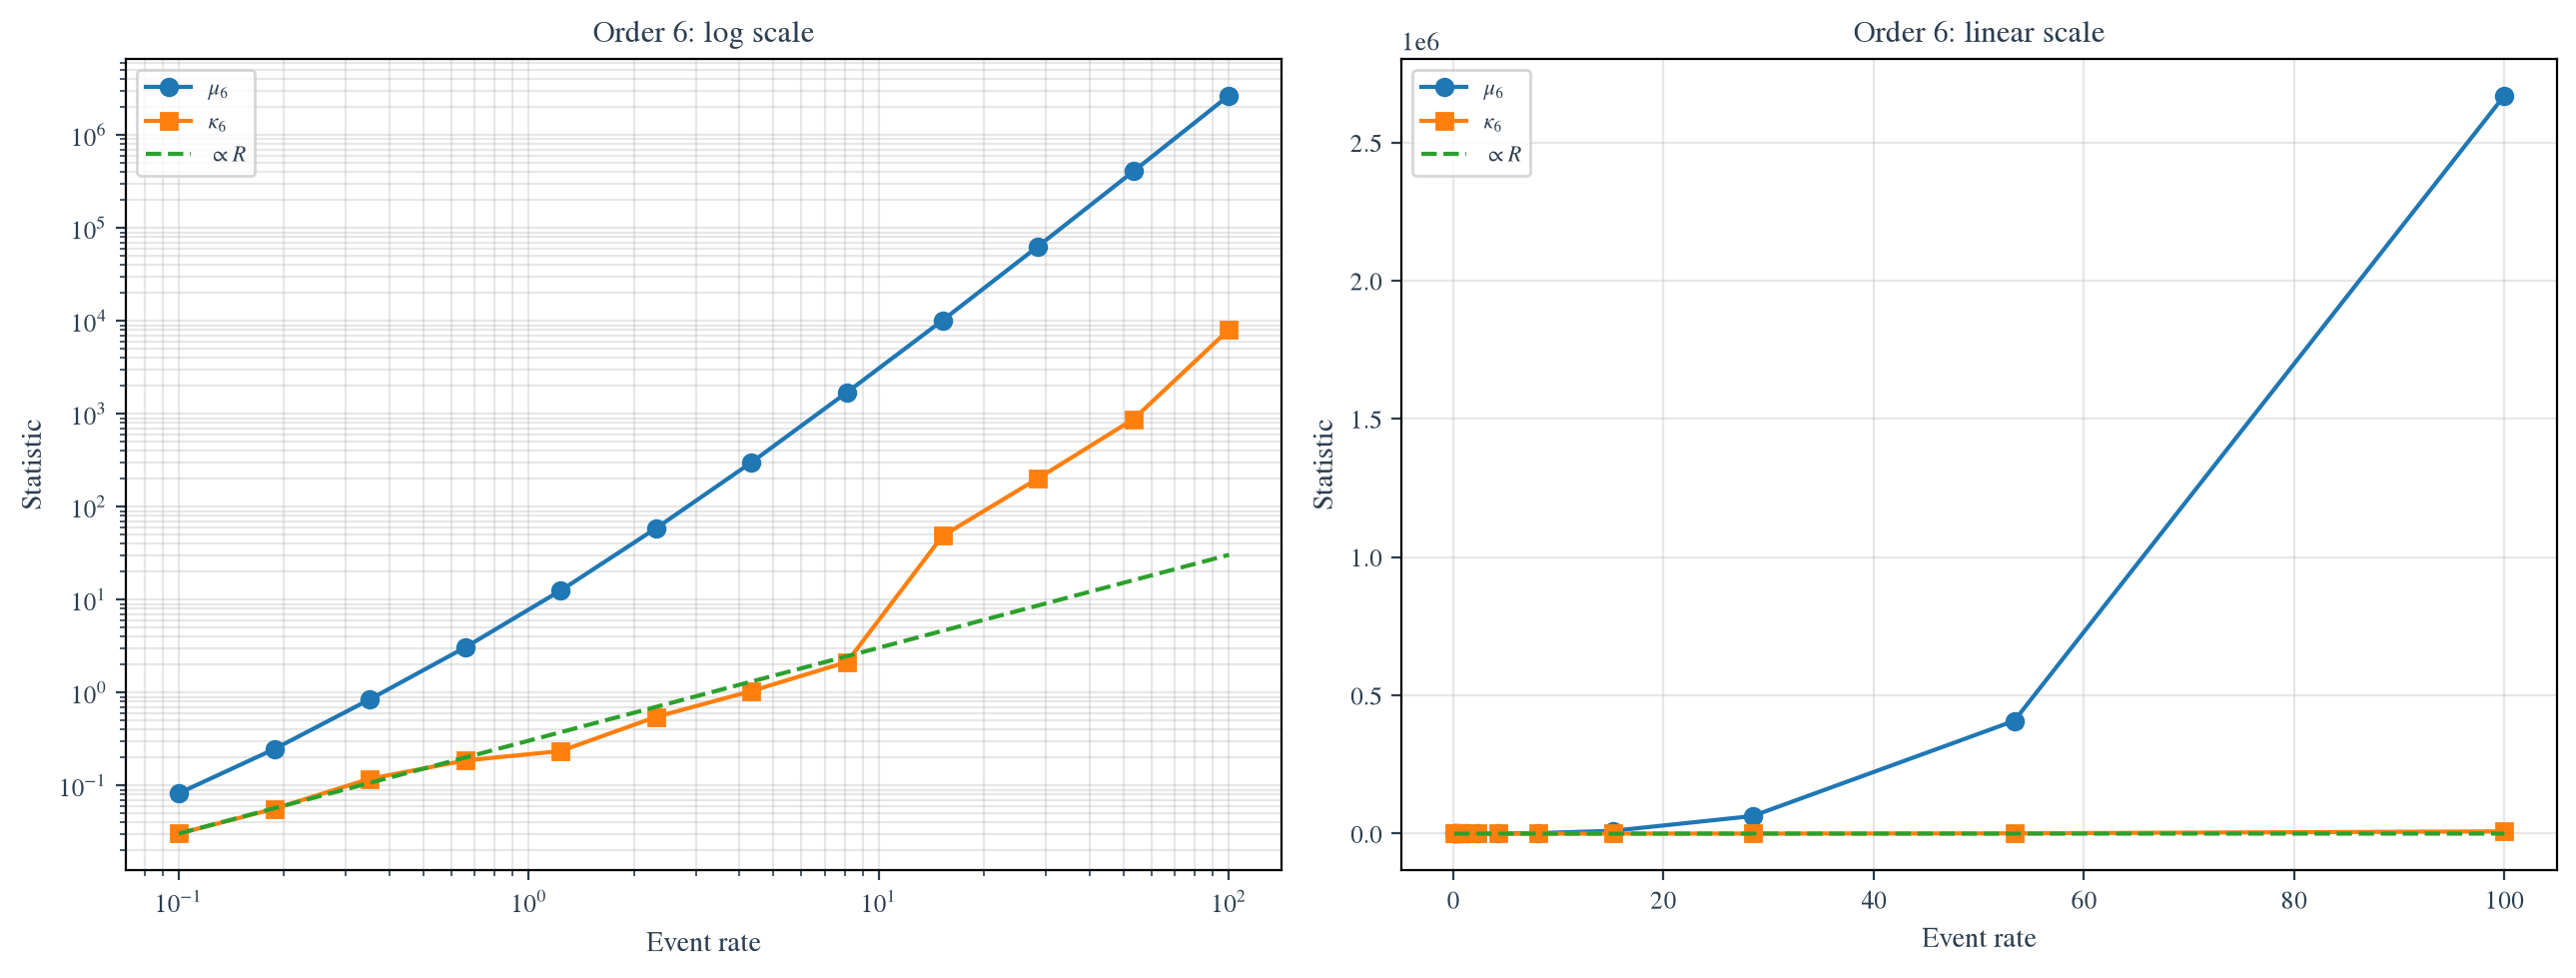

In [100]:
# Rate scaling:
# moments and cumulants & event rate

import math

rates_test = np.logspace(-1, 2, 12)
orders = np.arange(2, 7)
N_MC = 2000

moment_results = {n: np.zeros(len(rates_test)) for n in orders}
cumulant_results = {n: np.zeros(len(rates_test)) for n in orders}

spectrum_type = 'gaussian'


for ir, rate in enumerate(rates_test):

    moment_mc = {n: [] for n in orders}
    cumulant_mc = {n: [] for n in orders}

    for i in range(N_MC):

        s = generate_single_realization(rate, lambda n, sp=spectrum_type: sample_spectrum(sp, n))

        x = s - np.mean(s)

        mu = {n: np.mean(x**n) for n in orders}


        # CGF cumulant
        x_scale = np.std(x)
        t_values = np.linspace(-0.05/x_scale, 0.05/x_scale, 21)

        K = np.array([np.log(np.mean(np.exp(t*x))) for t in t_values])

        coeff = np.polynomial.polynomial.polyfit(t_values, K, max(orders))

        kappa = {n: math.factorial(n)*coeff[n] for n in orders}


        for n in orders:
            moment_mc[n].append(mu[n])
            cumulant_mc[n].append(kappa[n])


    for n in orders:
        moment_results[n][ir] = np.mean(moment_mc[n])
        cumulant_results[n][ir] = np.mean(cumulant_mc[n])



# plot

for n in orders:

    fig, axes = plt.subplots(1,2,figsize=(13,5),dpi=200)

    ref = np.abs(cumulant_results[n][0])*rates_test/rates_test[0]


    ax = axes[0]

    ax.loglog(rates_test,np.abs(moment_results[n]),'o-',label=fr'$\mu_{n}$')
    ax.loglog(rates_test,np.abs(cumulant_results[n]),'s-',label=fr'$\kappa_{n}$')
    ax.loglog(rates_test,ref,'--',label=r'$\propto R$')

    ax.set_xlabel("Event rate")
    ax.set_ylabel("Statistic")
    ax.set_title(fr"Order {n}: log scale")
    ax.grid(True,which="both",alpha=0.3)
    ax.legend()


    ax = axes[1]

    ax.plot(rates_test,np.abs(moment_results[n]),'o-',label=fr'$\mu_{n}$')
    ax.plot(rates_test,np.abs(cumulant_results[n]),'s-',label=fr'$\kappa_{n}$')
    ax.plot(rates_test,ref,'--',label=r'$\propto R$')

    ax.set_xlabel("Event rate")
    ax.set_ylabel("Statistic")
    ax.set_title(fr"Order {n}: linear scale")
    ax.grid(True,alpha=0.3)
    ax.legend()


    plt.tight_layout()
    plt.show()

## Part2:收敛速度
按理来说，对于任一阶矩（中心矩和原点矩都如此）
$$\hat{m}_n = \frac{1}{K} \sum_{i=1}^K x_i^n$$
由于稀疏取点的时候满足iid，所以看方差
$$\operatorname{Var}\left( \hat{m}_n \right) = \frac{1}{K^2} \cdot \left[ K \cdot \operatorname{Var}(Y) \right] = \frac{\operatorname{Var}(Y)}{K} \propto K^{-1}$$
按理来说，所有阶矩的收敛速度都是一样的？都是$-\frac{1}{2}$次幂。
而所有阶矩的方差也应当完全类似，按照$-1$次幂来收敛。
事实上，完整的收敛速度还应该考虑Rate：
对于 event rate 为 $R$ 的 compound-Poisson 信号，第 $n$ 阶 cumulant 对 $R$ 是线性的：
$$\kappa_n = C_n R,$$
其中 $C_n$ 与事件率无关。特别地
$$\kappa_2 = C_2 R, \quad \sigma_X^2 = \kappa_2 \propto R.$$
计算cumulant是使用的是n个样本
$$\mathrm{Var}(\hat{\kappa}_n) \propto \frac{\sigma_X^{2n}}{N}.$$
于是
$$\sigma_{\hat{\kappa}_n} \equiv \sqrt{\mathrm{Var}(\hat{\kappa}_n)} \simeq \sqrt{\frac{1}{N}} \sigma_X^n.$$
即
$$\sigma_{\hat{\kappa}_n} \simeq \sqrt{\frac{n!}{N}} (C_2 R)^{n/2}$$
$$\sigma_{\hat{\kappa}_n} \propto \frac{R^{n/2}}{\sqrt{N}}.$$
除以cumulant
$$\frac{\sigma_{\hat{\kappa}_n}}{\vert{}\kappa_n\vert{}} \simeq \frac{(C_2 R)^{n/2}}{\sqrt{N} \vert{}C_n\vert{} R}.$$




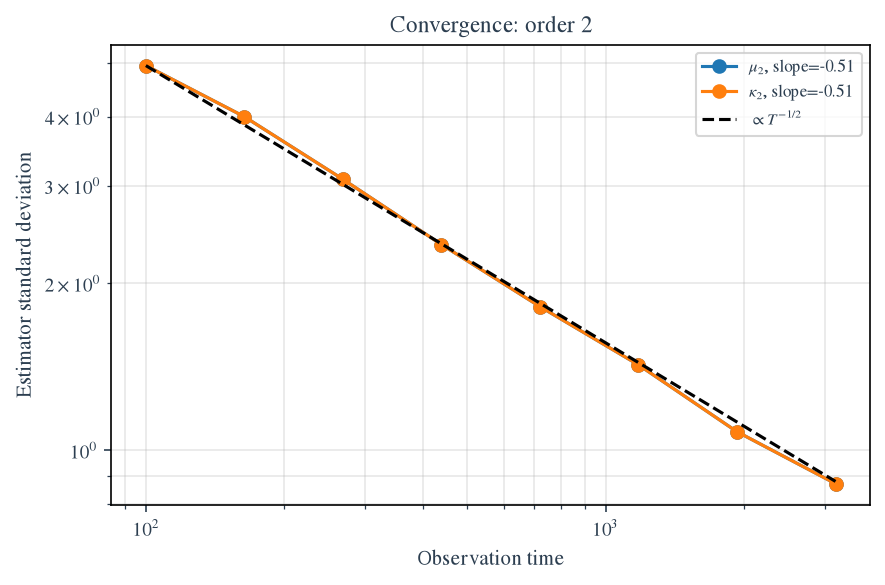

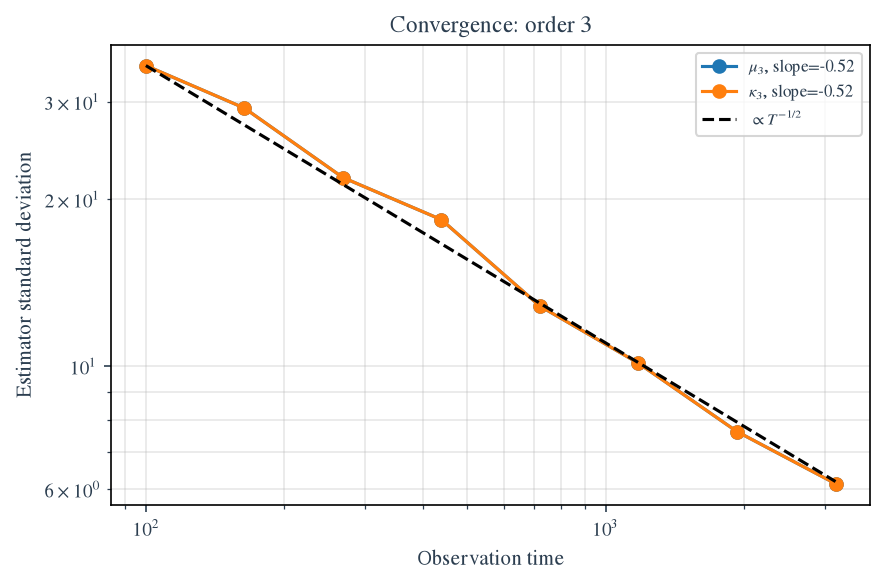

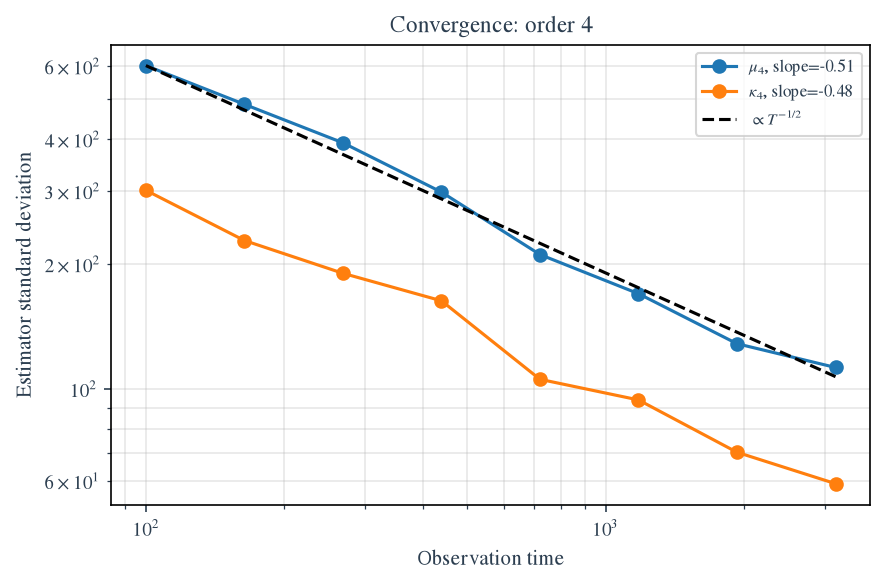

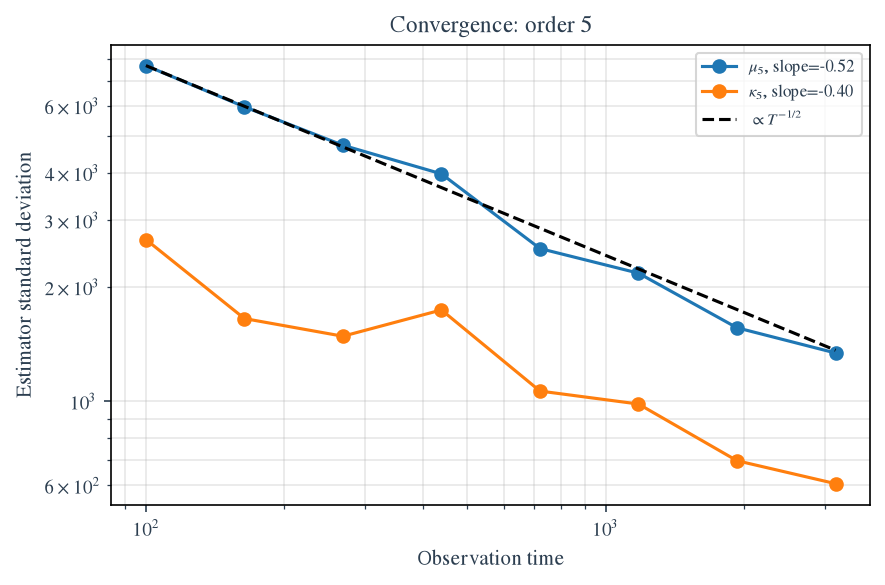

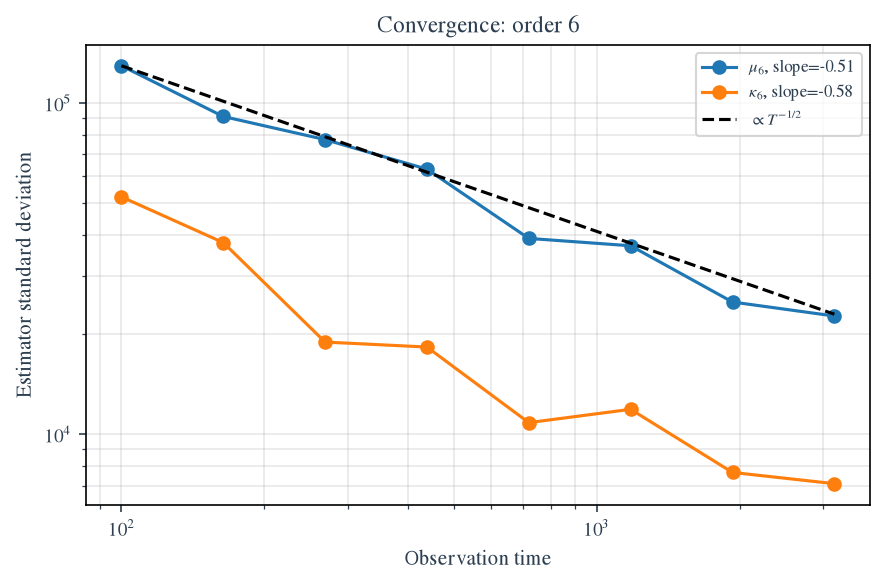

In [101]:
# Estimate convergence variances at different observation times
obs_times = np.logspace(2, 3.5, 8)
N_MC_convergence = 300
convergence_rate = 30.0

moment_var = {n: [] for n in orders}
cumulant_var = {n: [] for n in orders}

for obs_time in obs_times:
    moment_mc = {n: [] for n in orders}
    cumulant_mc = {n: [] for n in orders}

    for _ in range(N_MC_convergence):
        s = generate_single_realization(
            convergence_rate,
            lambda k: sample_spectrum(spectrum_type, k),
            observation_time=obs_time
        )
        x = s - np.mean(s)
        m = {n: np.mean(x**n) for n in orders}
        kappa = {
            2: m[2],
            3: m[3],
            4: m[4] - 3*m[2]**2,
            5: m[5] - 10*m[3]*m[2],
            6: m[6] - 15*m[4]*m[2]
               - 10*m[3]**2 + 30*m[2]**3
        }

        for n in orders:
            moment_mc[n].append(m[n])
            cumulant_mc[n].append(kappa[n])

    for n in orders:
        moment_var[n].append(np.var(moment_mc[n], ddof=1))
        cumulant_var[n].append(np.var(cumulant_mc[n], ddof=1))

for n in orders:
    plt.figure(figsize=(6, 4), dpi=150)

    for var, label in [
        (moment_var[n], fr'$\mu_{n}$'),
        (cumulant_var[n], fr'$\kappa_{n}$')
    ]:
        std = np.sqrt(var)
        slope = np.polyfit(np.log(obs_times), np.log(std), 1)[0]

        plt.loglog(obs_times, std, 'o-',
                   label=f'{label}, slope={slope:.2f}')

    ref = np.sqrt(moment_var[n][0]) * (obs_times / obs_times[0])**(-0.5)
    plt.loglog(obs_times, ref, 'k--', label=r'$\propto T^{-1/2}$')

    plt.xlabel('Observation time')
    plt.ylabel('Estimator standard deviation')
    plt.title(f'Convergence: order {n}')
    plt.grid(True, which='both', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

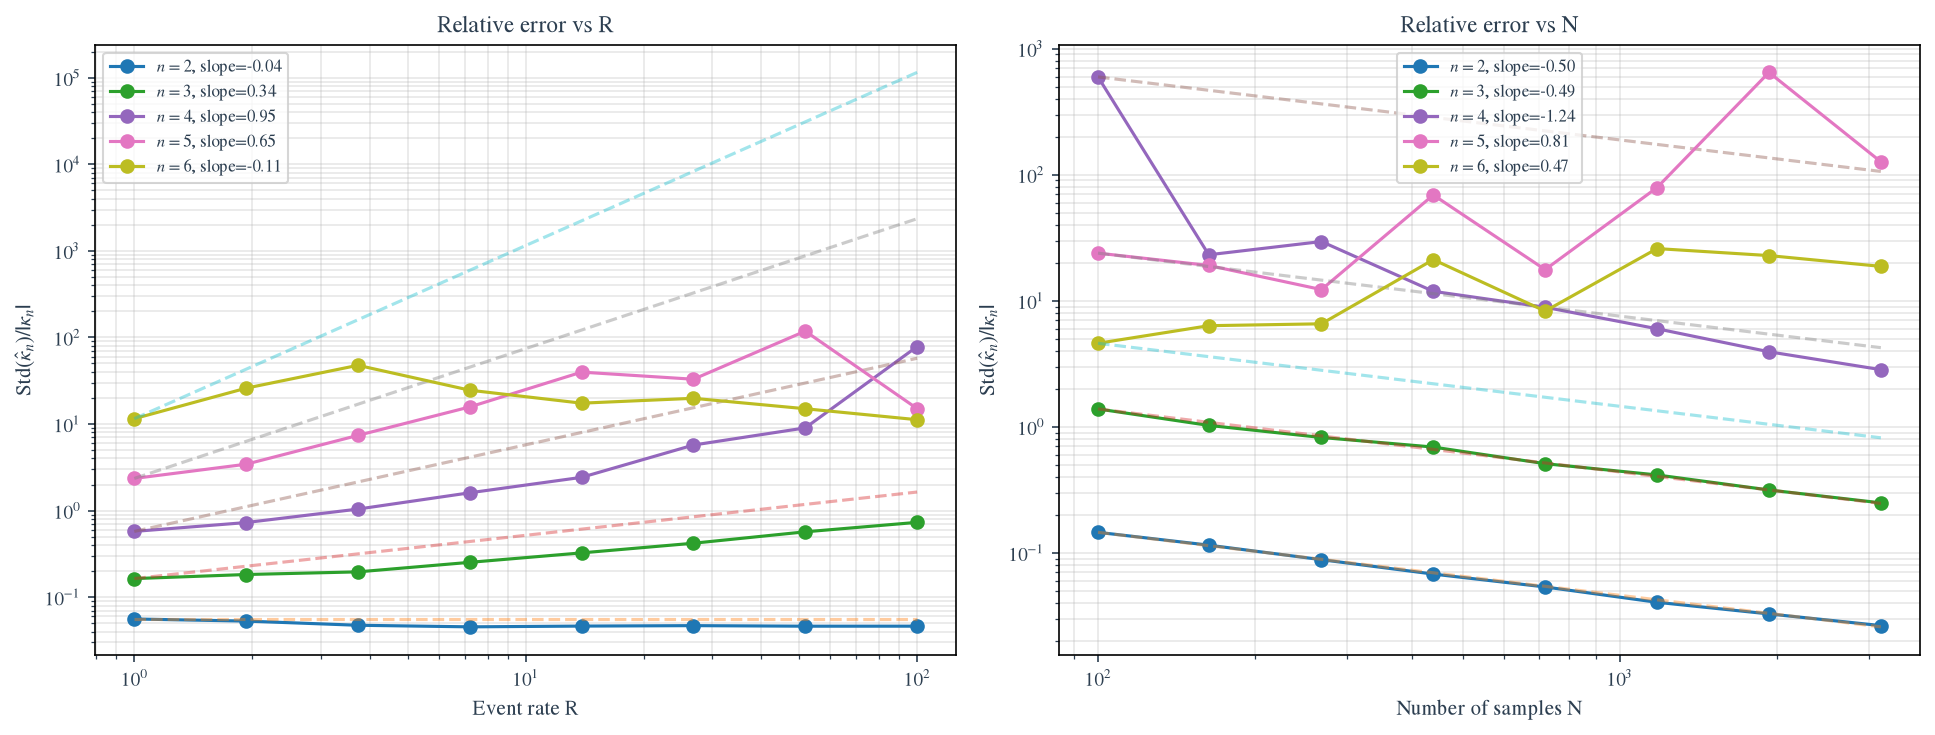

In [102]:
# Relative-error scaling with R and N

orders = np.arange(2, 7)
rates = np.logspace(0, 2, 8)
Ns = np.unique(np.logspace(2, 3.5, 8).astype(int))
N_MC = 1000
spectrum_type = 'gaussian'

R_fixed = 30.0
N_fixed = 1000

results = {}

for mode, values in [('R', rates), ('N', Ns)]:
    errors = {n: [] for n in orders}

    for value in values:
        R = value if mode == 'R' else R_fixed
        N = N_fixed if mode == 'R' else int(value)

        # Generate enough data for N sparsely sampled points
        observation_time = N * t_step

        mc = {n: [] for n in orders}

        for _ in range(N_MC):
            s = generate_single_realization(
                R, lambda k: sample_spectrum(spectrum_type, k),
                observation_time=observation_time
            )[:N]

            x = s - s.mean()
            m = {n: np.mean(x**n) for n in orders}

            kappa = {
                2: m[2],
                3: m[3],
                4: m[4] - 3*m[2]**2,
                5: m[5] - 10*m[3]*m[2],
                6: m[6] - 15*m[4]*m[2]
                   - 10*m[3]**2 + 30*m[2]**3
            }

            for n in orders:
                mc[n].append(kappa[n])

        for n in orders:
            a = np.asarray(mc[n])
            errors[n].append(a.std(ddof=1) / abs(a.mean()))

    results[mode] = errors


# Plot measured slopes against theoretical slopes

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

for ax, mode, values in zip(
    axes, ['R', 'N'], [rates, Ns]
):
    for n in orders:
        y = np.asarray(results[mode][n])
        slope = np.polyfit(np.log(values), np.log(y), 1)[0]
        expected = n/2 - 1 if mode == 'R' else -0.5

        ax.loglog(values, y, 'o-',
                  label=fr'$n={n}$, slope={slope:.2f}')

        ref = y[0] * (values / values[0])**expected
        ax.loglog(values, ref, '--', alpha=0.4)

    ax.set_xlabel('Event rate R' if mode == 'R'
                  else 'Number of samples N')
    ax.set_ylabel(r'$\mathrm{Std}(\hat{\kappa}_n)/|\kappa_n|$')
    ax.set_title(f'Relative error vs {mode}')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# 双通道高阶 Cross Cumulant

考虑两个探测通道

$$
X_1=S_1+N_1,\qquad X_2=S_2+N_2,
$$

其中 $S_1,S_2$ 来自共同的 DM 事件，因此两个通道中的信号是相关的；而两个通道的加性探测器噪声相互独立：

$$
N_1\perp N_2,
\qquad
N_a\perp S.
$$

双通道的联合 cumulant generating function 定义为

$$
K(t_1,t_2)
=
\log
\left\langle
e^{t_1X_1+t_2X_2}
\right\rangle .
$$

定义 mixed cumulant

$$
\kappa_{p,q}
=
\left.
\frac{\partial^{p+q}K}
{\partial t_1^p\partial t_2^q}
\right|_{t_1=t_2=0},
$$

其中总阶数为

$$
n=p+q.
$$

只要 $p,q\geq1$，由于两个通道的加性噪声相互独立，单通道噪声不会贡献 cross cumulant：

$$
\boxed{
\kappa_{p,q}(X_1,X_2)
=
\kappa_{p,q}(S_1,S_2)
}.
$$

因此 cross cumulant 可以在期望值层面消除两个通道各自独立的白噪声。


## 二阶 Cross Cumulant

令两个通道中心化后的变量为

$$
x_1=X_1-\langle X_1\rangle,
\qquad
x_2=X_2-\langle X_2\rangle.
$$

二阶只有一种非平凡的 cross 结构：

$$
\boxed{
\kappa_2^{\rm cross}
=
\kappa_{1,1}
=
\langle x_1x_2\rangle
}.
$$

对于共同的 compound-Poisson DM signal，

$$
\kappa_{1,1}
=
R\left\langle A_1A_2\right\rangle,
$$

因此

$$
\boxed{
\kappa_2^{\rm cross}\propto R
}.
$$


## 三阶 Cross Cumulant

三阶存在两种 mixed cumulant：

$$
\kappa_{2,1}
=
\operatorname{cum}(X_1,X_1,X_2),
$$

以及

$$
\kappa_{1,2}
=
\operatorname{cum}(X_1,X_2,X_2).
$$

对于中心化变量，三阶 cumulant 等于三阶 central moment，因此

$$
\kappa_{2,1}
=
\langle x_1^2x_2\rangle,
\qquad
\kappa_{1,2}
=
\langle x_1x_2^2\rangle.
$$

对于两个对称通道，定义对称的三阶 cross cumulant：

$$
\boxed{
\kappa_3^{\rm cross}
=
\frac{1}{2}
\left(
\kappa_{2,1}+\kappa_{1,2}
\right)
}.
$$

对于 compound-Poisson signal，

$$
\kappa_{2,1}
=
R\left\langle A_1^2A_2\right\rangle,
\qquad
\kappa_{1,2}
=
R\left\langle A_1A_2^2\right\rangle,
$$

因此

$$
\boxed{
\kappa_3^{\rm cross}
=
\frac{R}{2}
\left[
\left\langle A_1^2A_2\right\rangle
+
\left\langle A_1A_2^2\right\rangle
\right]
\propto R
}.
$$


## 任意高阶的双通道定义

对于总阶数 $n$，采用尽可能平均地将阶数分配到两个通道的定义。

当 $n=2m$ 为偶数时，

$$
\boxed{
\kappa_n^{\rm cross}
=
\kappa_{m,m}
}.
$$

当 $n=2m+1$ 为奇数时，采用两个相邻分配的对称组合：

$$
\boxed{
\kappa_n^{\rm cross}
=
\frac{
\kappa_{m+1,m}
+
\kappa_{m,m+1}
}{2}
}.
$$

因此前几阶分别为

$$
\kappa_2^{\rm cross}=\kappa_{1,1},
$$

$$
\kappa_3^{\rm cross}
=
\frac{\kappa_{2,1}+\kappa_{1,2}}{2},
$$

$$
\kappa_4^{\rm cross}=\kappa_{2,2},
$$

$$
\kappa_5^{\rm cross}
=
\frac{\kappa_{3,2}+\kappa_{2,3}}{2},
$$

$$
\kappa_6^{\rm cross}=\kappa_{3,3}.
$$

对于 compound-Poisson DM signal，所有这些 mixed cumulant 都满足

$$
\boxed{
\kappa_n^{\rm cross}\propto R
}.
$$

因此可以完全类比单通道的分析，首先验证不同阶 cross cumulant 与 event rate $R$ 的线性关系，然后研究其有限样本收敛性质以及最终的参数估计精度。

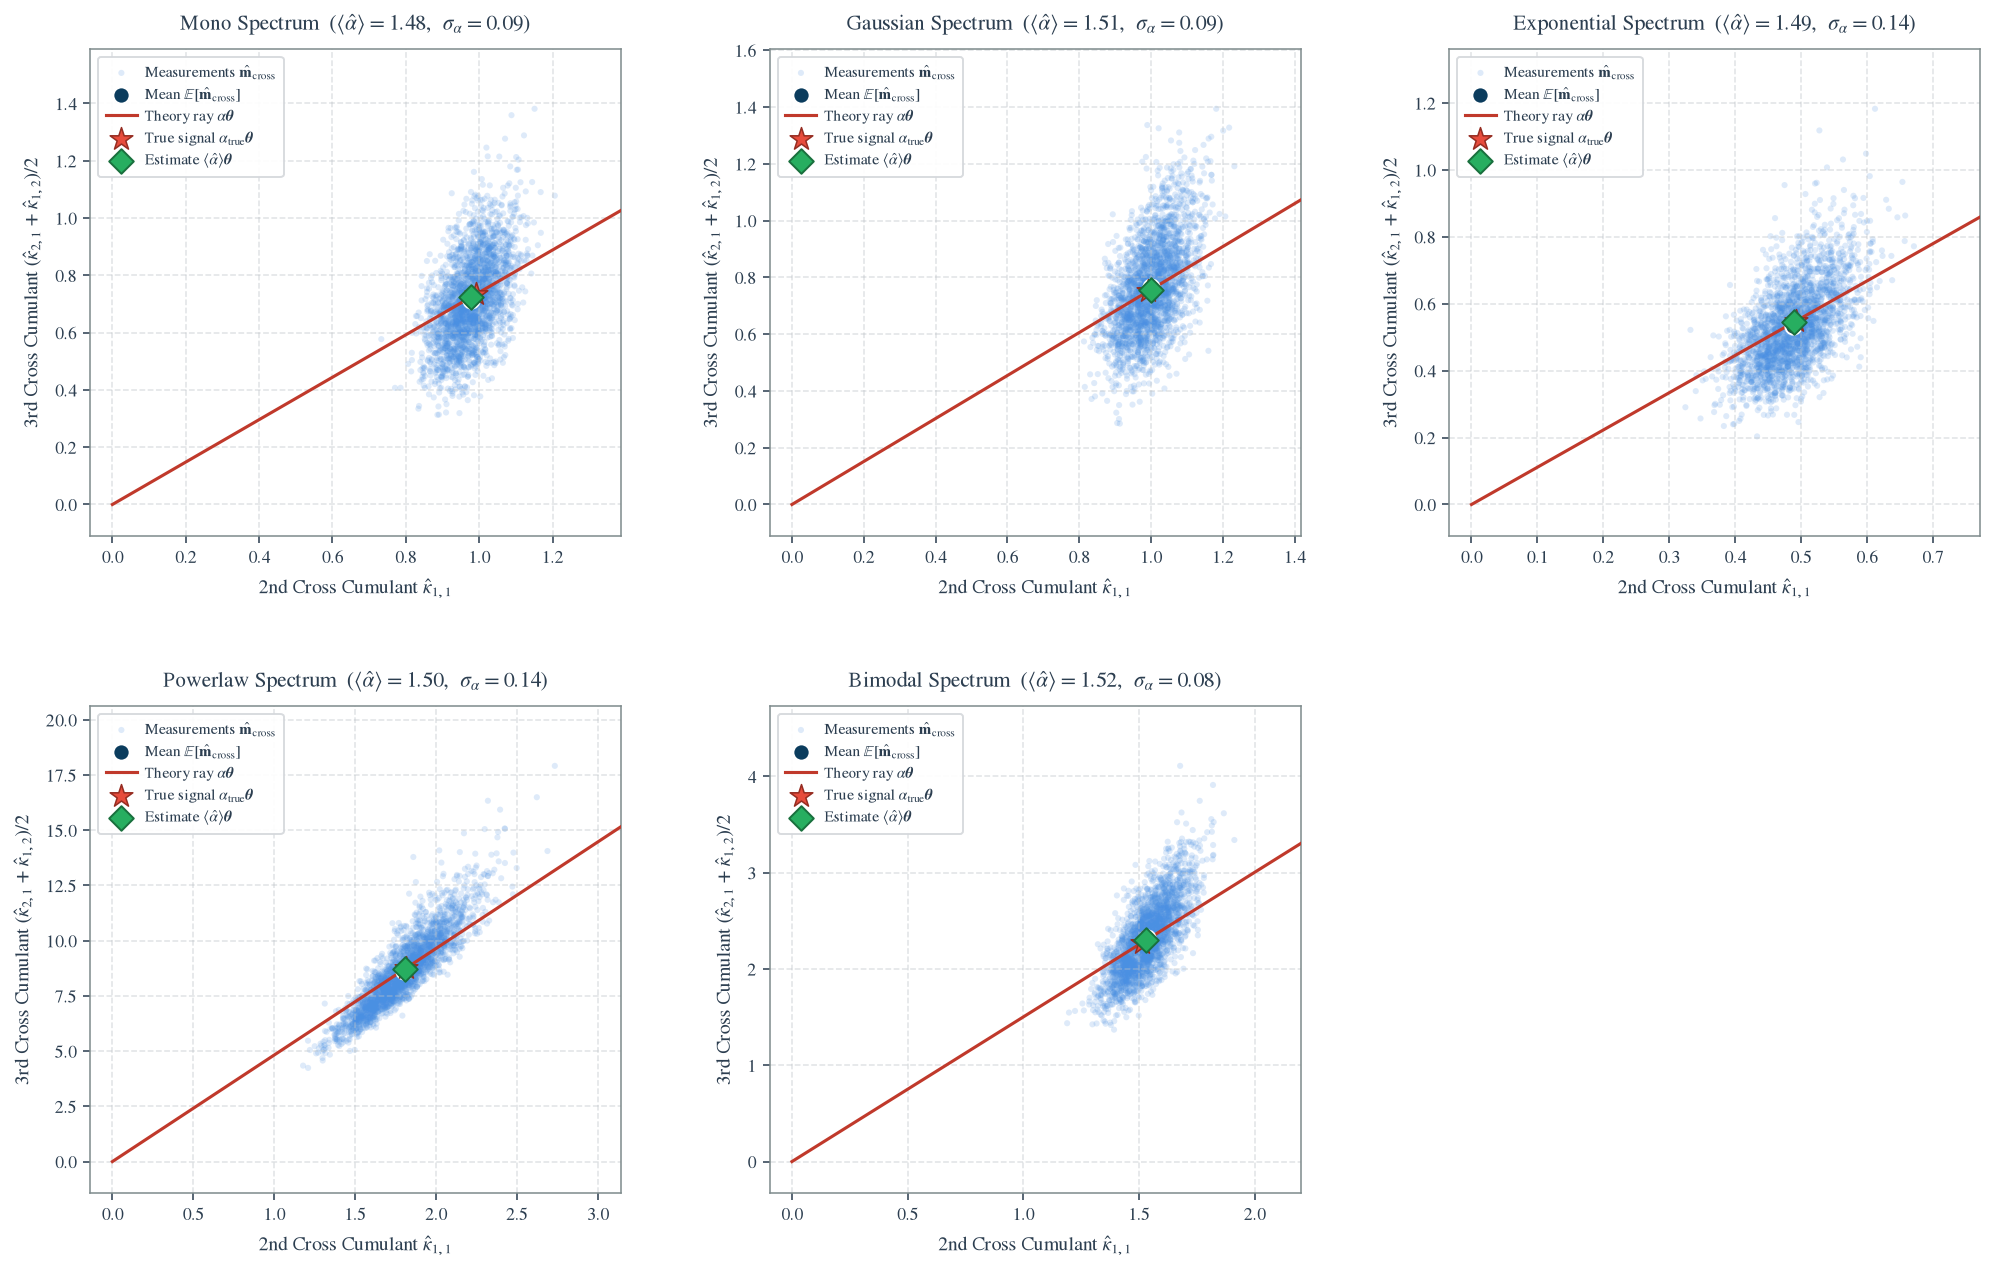

In [103]:
# Two-channel parameter estimation with cross cumulants
# rate=1.2Hz

def cal_cross_2d(x1, x2):

    x1 = x1 - np.mean(x1)
    x2 = x2 - np.mean(x2)

    # second-order cross cumulant
    k11 = np.mean(x1 * x2)

    # third-order cross cumulants
    k21 = np.mean(x1**2 * x2)
    k12 = np.mean(x1 * x2**2)

    # symmetric third-order cross cumulant
    k3_cross = 0.5 * (k21 + k12)

    return k11, k3_cross

def simulate_spectrum_experiment_2ch(spectrum_type, n_experiments=2500):

    # 1. Reference template theta at rate_0
    k2_ref_list = []
    k3_ref_list = []

    for _ in range(80):

        # Common DM realization
        s_ref = generate_single_realization(
            rate_0,
            lambda n, sp=spectrum_type: sample_spectrum(sp, n)
        )

        # For theta we only need the signal expectation.
        # Identical signal response in the two channels.
        k2_ref, k3_ref = cal_cross_2d(s_ref, s_ref)

        k2_ref_list.append(k2_ref)
        k3_ref_list.append(k3_ref)

    theta = np.array([
        np.mean(k2_ref_list),
        np.mean(k3_ref_list)
    ])

    # 2. Two-channel measurements at rate_true

    m_obs_list = []

    for _ in range(n_experiments):

        # Same DM realization enters both channels
        s_true = generate_single_realization(
            rate_true,
            lambda n, sp=spectrum_type: sample_spectrum(sp, n)
        )

        # Independent detector noise
        noise1 = np.random.normal(
            0.0, gauss_std, len(s_true)
        )

        noise2 = np.random.normal(
            0.0, gauss_std, len(s_true)
        )

        x1 = s_true + noise1
        x2 = s_true + noise2

        # Cross observables
        k2_cross, k3_cross = cal_cross_2d(x1, x2)

        m_obs_list.append([
            k2_cross,
            k3_cross
        ])


    m_obs_arr = np.asarray(m_obs_list)

    mean_obs = np.mean(m_obs_arr, axis=0)

    # 3. Covariance matrix

    Sigma = np.cov(
        m_obs_arr,
        rowvar=False
    )

    Sigma_inv = np.linalg.inv(Sigma)

    # 4. GLS estimator for alpha

    denom = theta.T @ Sigma_inv @ theta

    alpha_hats = (
        m_obs_arr @ Sigma_inv @ theta
    ) / denom


    return {
        'type': spectrum_type,
        'theta': theta,
        'm_obs_arr': m_obs_arr,
        'mean_obs': mean_obs,
        'Sigma': Sigma,
        'alpha_hats': alpha_hats,
        'alpha_true': alpha_true
    }

# Plot

def plot_all_spectra_2ch(
    output_name="two_channel_cross_estimation.png",
    n_experiments=2500
):

    spectra = [
        'mono',
        'gaussian',
        'exponential',
        'powerlaw',
        'bimodal'
    ]

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9.5),
        dpi=140
    )

    axes = axes.flatten()


    for i, spec in enumerate(spectra):

        ax = axes[i]

        res = simulate_spectrum_experiment_2ch(
            spec,
            n_experiments=n_experiments
        )

        theta = res['theta']
        m_obs = res['m_obs_arr']
        mean_obs = res['mean_obs']
        alpha_hats = res['alpha_hats']

        mean_alpha = np.mean(alpha_hats)
        std_alpha = np.std(alpha_hats, ddof=1)

        # Plot range

        true_pt = alpha_true * theta

        all_x = np.concatenate([
            m_obs[:, 0],
            [0.0, true_pt[0]]
        ])

        all_y = np.concatenate([
            m_obs[:, 1],
            [0.0, true_pt[1]]
        ])

        x_min, x_max = np.min(all_x), np.max(all_x)
        y_min, y_max = np.min(all_y), np.max(all_y)

        dx = x_max - x_min if x_max > x_min else 1.0
        dy = y_max - y_min if y_max > y_min else 1.0

        plot_x_min = min(0.0, x_min) - 0.05 * dx
        plot_x_max = x_max + 0.15 * dx

        plot_y_min = min(0.0, y_min) - 0.08 * dy
        plot_y_max = y_max + 0.15 * dy

        # Measurement cloud

        ax.scatter(
            m_obs[:, 0],
            m_obs[:, 1],
            color='#4A90E2',
            alpha=0.18,
            s=10,
            edgecolors='none',
            label=r'Measurements $\hat{\mathbf{m}}_{\rm cross}$'
        )

        # Mean measurement

        ax.scatter(
            mean_obs[0],
            mean_obs[1],
            color='#0B3C5D',
            s=70,
            marker='o',
            edgecolors='white',
            linewidth=1.0,
            zorder=5,
            label=r'Mean $\mathbb{E}[\hat{\mathbf{m}}_{\rm cross}]$'
        )

        # Theory ray alpha theta

        if np.abs(theta[0]) > 1e-12:
            scale_ray = plot_x_max / theta[0]
        else:
            scale_ray = 2.5

        ax.plot(
            [0.0, scale_ray * theta[0]],
            [0.0, scale_ray * theta[1]],
            color='#C0392B',
            lw=1.6,
            linestyle='-',
            zorder=4,
            label=r'Theory ray $\alpha\boldsymbol{\theta}$'
        )

        # True point

        ax.scatter(
            true_pt[0],
            true_pt[1],
            color='#E74C3C',
            marker='*',
            s=150,
            edgecolors='#962D22',
            linewidth=0.8,
            zorder=6,
            label=r'True signal $\alpha_{\rm true}\boldsymbol{\theta}$'
        )

        # Estimated point

        proj_pt = mean_alpha * theta

        ax.scatter(
            proj_pt[0],
            proj_pt[1],
            color='#27AE60',
            s=80,
            marker='D',
            edgecolors='#196F3D',
            linewidth=1.0,
            zorder=7,
            label=r'Estimate $\langle\hat{\alpha}\rangle\boldsymbol{\theta}$'
        )

        # Axes

        ax.set_xlim(
            plot_x_min,
            plot_x_max
        )

        ax.set_ylim(
            plot_y_min,
            plot_y_max
        )

        ax.set_xlabel(
            r'2nd Cross Cumulant $\hat{\kappa}_{1,1}$',
            labelpad=6
        )

        ax.set_ylabel(
            r'3rd Cross Cumulant '
            r'$(\hat{\kappa}_{2,1}+\hat{\kappa}_{1,2})/2$',
            labelpad=6
        )

        ax.set_title(
            f"{spec.capitalize()} Spectrum  "
            + rf"($\langle\hat{{\alpha}}\rangle={mean_alpha:.2f},"
            + rf"\ \sigma_\alpha={std_alpha:.2f}$)",
            pad=10
        )

        ax.grid(
            True,
            linestyle='--',
            color='#BDC3C7',
            alpha=0.45,
            zorder=0
        )

        for spine in ax.spines.values():
            spine.set_color('#7F8C8D')
            spine.set_linewidth(0.8)

        ax.tick_params(
            direction='out',
            length=3.5,
            width=0.8
        )

        ax.legend(
            loc='upper left',
            frameon=True,
            facecolor='white',
            edgecolor='#D5D8DC',
            framealpha=0.92,
            borderpad=0.5,
            labelspacing=0.4,
            handletextpad=0.5
        )


    fig.delaxes(axes[5])

    plt.subplots_adjust(
        left=0.07,
        right=0.97,
        bottom=0.08,
        top=0.94,
        wspace=0.28,
        hspace=0.35
    )

    plt.savefig(
        output_name,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


rate_0 = 1.2
rate_true = alpha_true * rate_0

plot_all_spectra_2ch(
    "two_channel_low_rate_cross_estimation.png",
    n_experiments=2500
)

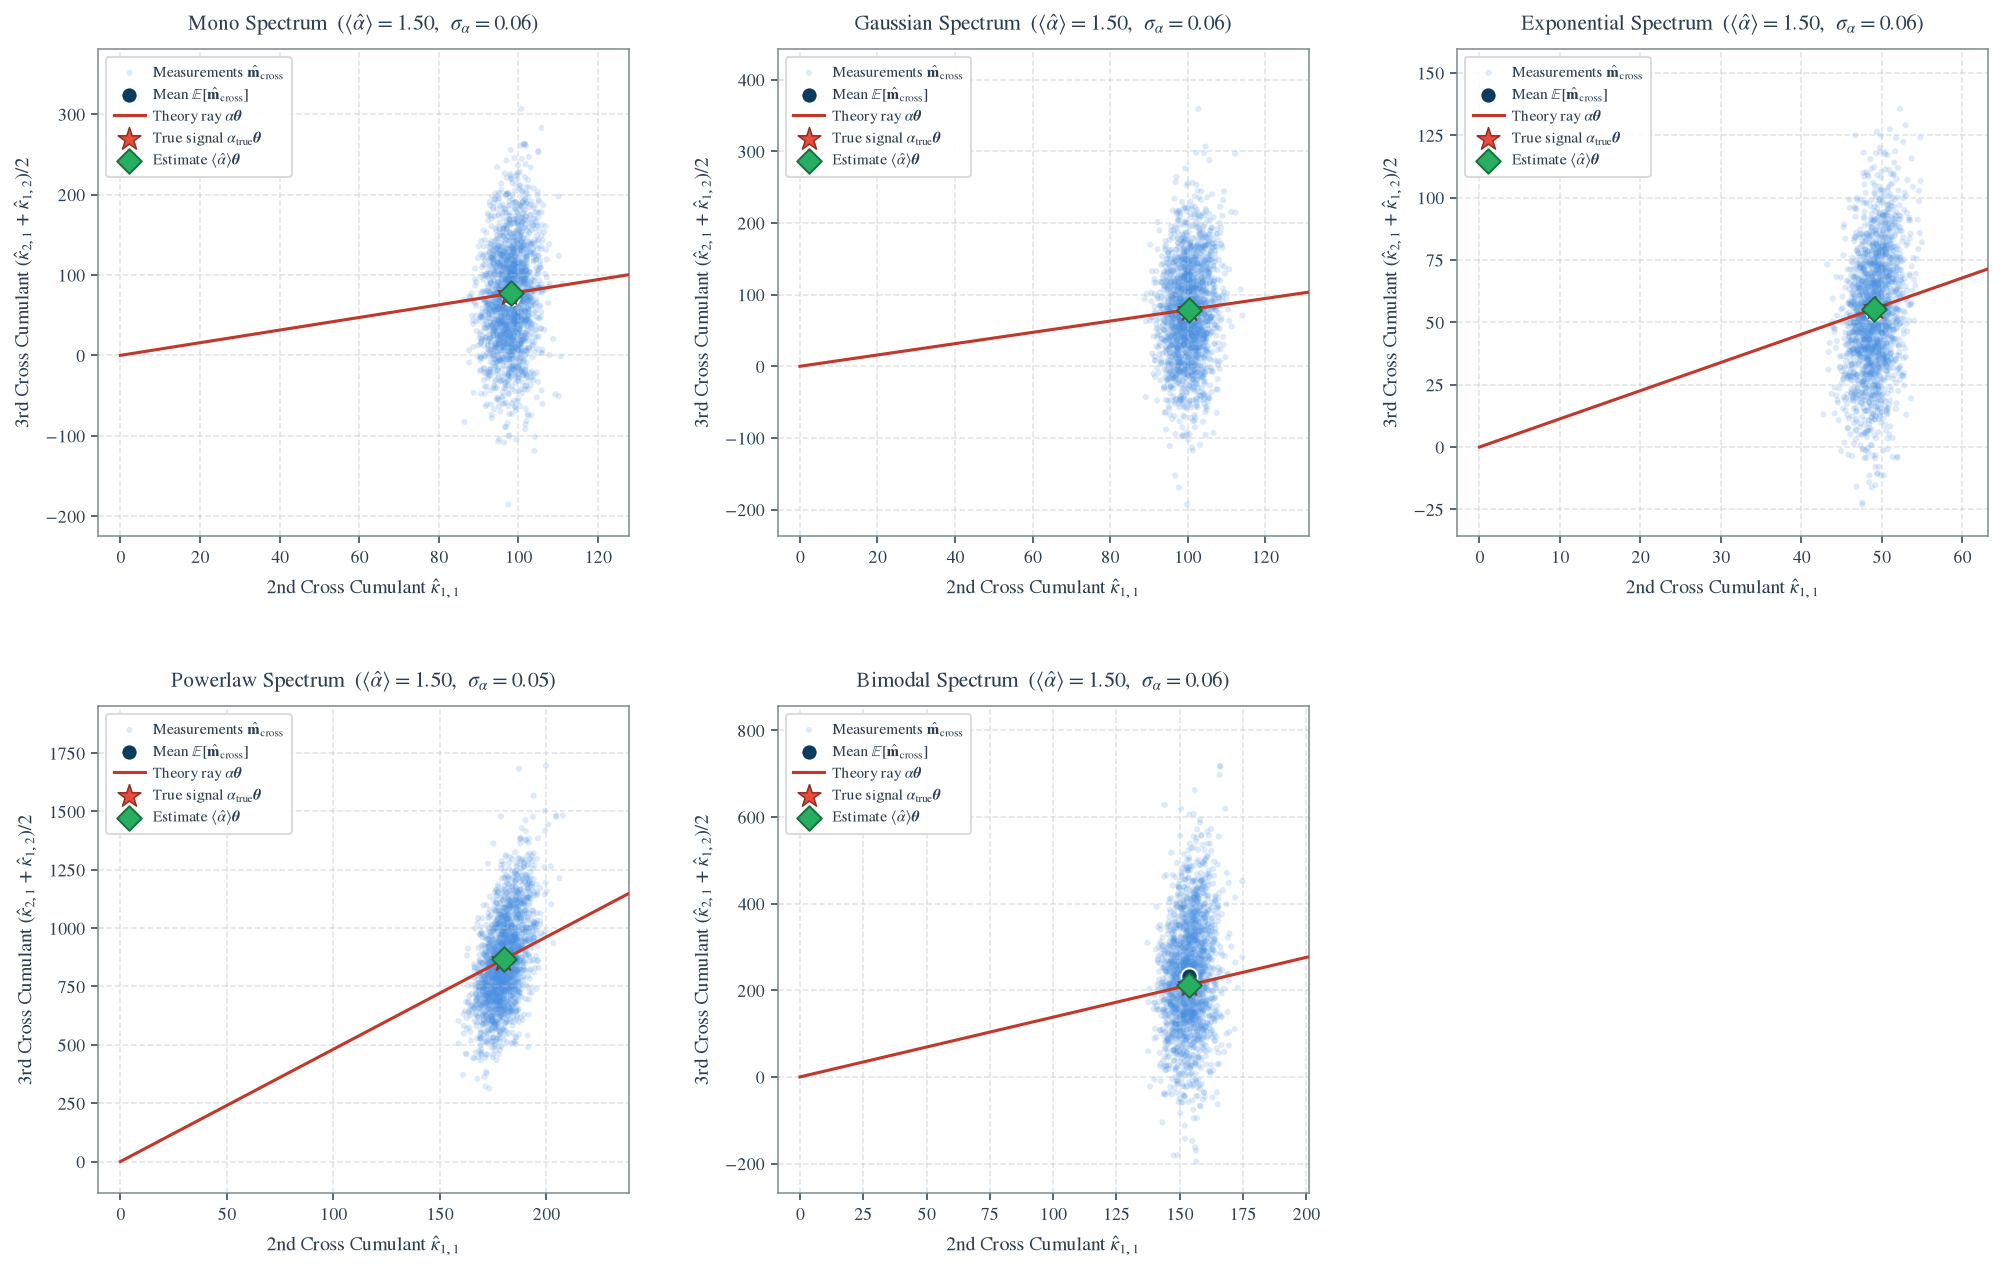

In [104]:
# High-rate case: two-channel cross-cumulant estimator
rate_0 = 120.0
rate_true = alpha_true * rate_0

plot_all_spectra_2ch(
    "two_channel_high_rate_cross_estimation.png",
    n_experiments=2000
)

## 查看和trigger的等价性
连续波形按宽度 $T_{\text{bin}} = W \cdot \mathrm{d}t$ 划分为 $K$ 个连续的bin，第 $k$ 个bin里考虑
$$y_k = \int_{k T_{\mathrm{bin}}}^{(k+1) T_{\mathrm{bin}}} x(t) \, \mathrm{d}t = s_k + n_k$$
threshold设为$4\sigma$，均值之上直接计数


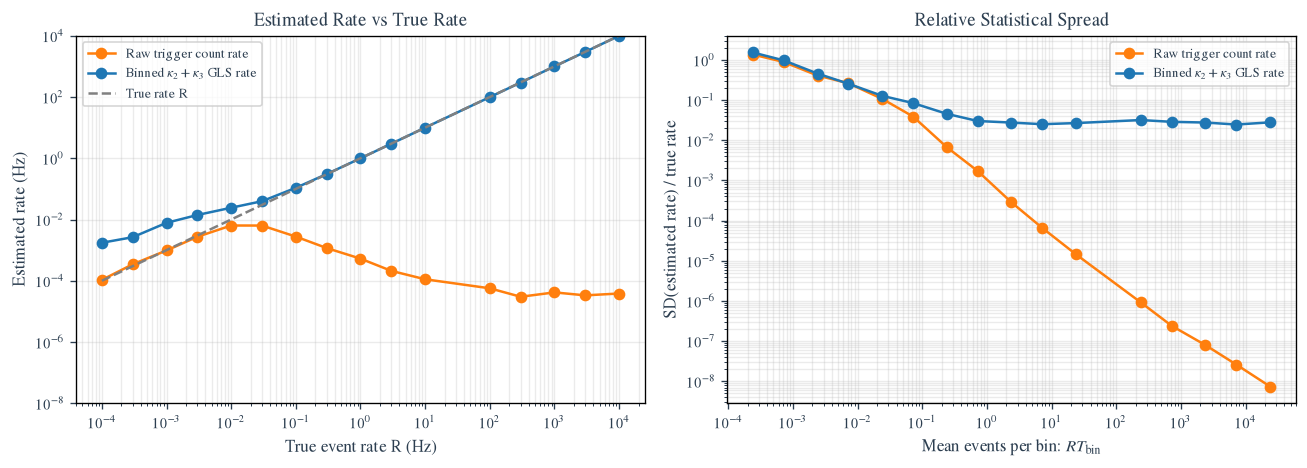

theta_kappa = [186.55578603 137.72222783]


In [108]:
np.random.seed(2026)
spectrum = 'gaussian'
rates = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0, 10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0])
N_MC = 100
W = round(3 * tau_f / dt)
K = int(t_obs / (W * dt))
T_bin = W * dt

def generate_single_raw(rate_val, energies_func, observation_time=None):
    """
    和前面的一样
    """
    local_t_obs = t_obs if observation_time is None else float(observation_time)
    local_t_total = t_burn + local_t_obs + t_pulse_len
    local_N_pts = int(np.ceil(local_t_total / dt))
    local_i_end = int((t_burn + local_t_obs) / dt)

    n_events = np.random.poisson(rate_val * local_t_total)
    t_events = np.random.uniform(0.0, local_t_total, n_events)
    e_events = energies_func(n_events)
    
    delta_train = np.zeros(local_N_pts, dtype=np.float64)
    indices = np.clip((t_events / dt).astype(int), 0, local_N_pts - 1)
    np.add.at(delta_train, indices, e_events)
    
    s = fftconvolve(delta_train, template, mode='full')[:local_N_pts]#python的fft效率较低，可以使用效率更高的
    s_raw = s[i_start:local_i_end]
    return s_raw

# theoretical
kappa_mc = np.empty((N_MC, 2))
for i in range(N_MC):
    s = generate_single_raw(rate_0, lambda n: sample_spectrum(spectrum, n))
    yk = s[:K*W].reshape(K, W).sum(axis=1) * dt
    c = yk - yk.mean()
    kappa_mc[i, 0] = np.mean(c**2)
    kappa_mc[i, 1] = np.mean(c**3)
theta_kappa = kappa_mc.mean(axis=0)

R_kappa = {R: [] for R in rates}
trig    = {R: [] for R in rates}

for R in rates:
    # MC
    kappa_mc_R = np.empty((N_MC, 2))
    y_mc       = np.empty((N_MC, K))
    for i in range(N_MC):
        s = generate_single_raw(R, lambda n: sample_spectrum(spectrum, n))
        x = s + np.random.normal(0.0, gauss_std, s.shape)
        yk = x[:K*W].reshape(K, W).sum(axis=1) * dt
        y_mc[i] = yk
        c = yk - yk.mean()
        kappa_mc_R[i, 0] = np.mean(c**2)
        kappa_mc_R[i, 1] = np.mean(c**3)

    Sinv_kappa = np.linalg.inv(np.cov(kappa_mc_R.T) + 1e-10 * np.eye(2))
    denom_k    = theta_kappa @ Sinv_kappa @ theta_kappa

    mu_y  = y_mc.mean(axis=0)
    sig_y = y_mc.std(axis=0)
    thr   = mu_y + 4 * sig_y

    for _ in range(N_MC):
        s = generate_single_raw(R, lambda n: sample_spectrum(spectrum, n))
        x = s + np.random.normal(0.0, gauss_std, s.shape)
        y = x[:K*W].reshape(K, W).sum(axis=1) * dt

        c = y - y.mean()
        kappa_hat = np.array([np.mean(c**2), np.mean(c**3)])
        R_2 = rate_0 * (theta_kappa @ Sinv_kappa @ kappa_hat) / denom_k
        R_kappa[R].append(R_2)

        R_trig = np.mean(y > thr) / T_bin
        trig[R].append(R_trig)

# plot
fig, ax = plt.subplots(1, 2, figsize=(11, 4), dpi=120)

styles = [
    ('Raw trigger count rate',               'tab:orange'),
    (r'Binned $\kappa_2+\kappa_3$ GLS rate', 'tab:blue'),
]

mean_rate = np.column_stack([
    [np.mean(trig[R])    for R in rates],
    [np.mean(R_kappa[R]) for R in rates],
])
spread = np.column_stack([
    [np.std(trig[R])    / R for R in rates],
    [np.std(R_kappa[R]) / R for R in rates],
])
occupancy = np.array(rates) * T_bin

for k, (name, color) in enumerate(styles):
    ax[0].plot(rates, mean_rate[:, k], 'o-', color=color, label=name)
    ax[1].loglog(occupancy, spread[:, k], 'o-', color=color, label=name)

ax[0].plot(rates, rates, '--', color='gray', label='True rate R')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_ylim(1e-8, 1e4)
ax[0].set(xlabel='True event rate R (Hz)',
          ylabel='Estimated rate (Hz)',
          title='Estimated Rate vs True Rate')
ax[1].set(xlabel=r'Mean events per bin: $R T_{\rm bin}$',
          ylabel='SD(estimated rate) / true rate',
          title='Relative Statistical Spread')

for a in ax:
    a.grid(True, which='both', alpha=0.25)
    a.legend()

plt.tight_layout(); plt.show()

print("theta_kappa =", theta_kappa)
if np.any(mean_rate <= 0):
    print("Note: zero/negative mean estimates are not visible on a log y-axis.")

1.估计中心值和variance的收敛速度

2.2个channel，如何定义高阶？尝试一下，目前的想法是，2个channel的目的是为了消去自相关的白噪声，对于偶数阶是好办的（只需要次数/2即可），对于奇数阶，只需要给出对称的结构就行，至于次数的选取，可以选取收敛速度最快的那一项。

3.关于cumulant
1）cumulant是否常用；2）cumulant在频域上是否好算？

4.在低事例率情况下，还要展示与trigger的等效性（低事例率的情况下理应要和trigger相等？）对比一定要对比相同的变量，一定要给出无偏估计，所以直接将整个trace按照特征时间分成很多个bin，计算能量作为这个bin的值，然后在 比如4sigma（窗口大约是10倍特征时间）

5.不同的背景下，sensitivity好不好：举很多个例子，要求moment/cumulant表现行为很不一样的；背景是没有backgroud、+gaussian、+powerlaw

6.最后看phonon bunching（efficiency）

逻辑：
1.原来的办法在高事例率情况下不适用，原因是pile up和trigger不可能，所以我们要思考如何通过不分辨单一事件的手段来定义一个正比于Rate的统计量来进行limit；
2.说明moment/cumulant和psd既可以测又可以算；强调各阶矩联合的运算应当可以代表包括能谱形状的信息，所以和trigger是等价的（最好数学上能证明）；
3.举例子，单通道/双通道/bkg等等；
4.对比这种方法和传统方法的区别（例如trigger、连续的功率计）

basic
1.为什么用cumulant
2.各阶矩做估计实际上是什么？
3.讨论收敛速度
4.和trigger的对比
5.保证是估计是保守的（找到反例？三阶矩为负的能谱会不会不保守）
6.2ch、不同的background下是什么情况

ref
1.相关暗物质实验的可行性；
2.cumulant等，数学证明过程等有关的文献，想办法把数学过程形式化；

## 1.扫描threshold的范围
间隔取点，只去threshold以上的点来计算，看看效果。
但是这样子会破坏normalization

## 2.时域上的信号&能谱的对应关系

## 3.为什么trigger和二阶矩、三阶矩过渡的不好


